# Level 6b — Delay equations with AUTO

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ZetaOne/pyauto-xpp/blob/main/tutorials/worked-examples/06b_delay-equations-with-auto.ipynb)

The second part of Level 6. [Part 6a](06a_delay-equations-simulation.ipynb)
(models 29–31) studied delay equations by simulation. Here XPPAUT 8.2's AUTO
works on them directly: it follows equilibria and judges their stability from
the *characteristic roots* (the roots of a transcendental equation such as
$\lambda = -r e^{-\lambda}$, infinitely many of them), locates Hopf points,
continues periodic orbits with their Floquet multipliers, follows Hopf, fold,
period-doubling and torus points in two parameters, and finds torus
(Neimark–Sacker) bifurcations of periodic orbits.

| | model | what it shows |
|---|---|---|
| [32](#two-delays) | linear equation with two delays | characteristic roots, Hopf points with two delays |
| [33](#hutchinson-periodic-orbits) | Hutchinson equation | Hopf point and the branch of periodic orbits, against simulations |
| [34](#cusp-delay) | cusp with a delay | folds, delay-induced Hopf points, a fold curve in $(a, b)$ |
| [35](#marcus-westervelt) | two delay-coupled neurons | Hopf points and the $(a, \tau)$ Hopf curves |
| [36](#wilson-cowan-delay) | Wilson–Cowan with delay | the $(P, \tau)$ Hopf curve, orbits against simulations |
| [37](#mackey-glass-period-doubling) | Mackey–Glass | period-doubling cascade, PD curve in $(\beta, \tau)$ |
| [38](#stuart-landau-single) | delayed Stuart–Landau | rotating waves, their folds and torus points |
| [39](#stuart-landau-pair) | two delay-coupled Stuart–Landau | torus bifurcations of the in-phase wave, torus curve |

**How to use this notebook.** Run the cells from the top (the first code cell
sets up helpers used by every section). Each section writes its model file to
`odes/<section>.ode` and its figures to `figures/<section>/`, and ends by
printing its checks. The last cell counts the checks of the whole notebook.
The continuations of models 38 and 39 take about a minute each.

**The history of a delay equation.** A delay equation needs its past, not
just a starting value. In XPP the past (for $t < 0$) is the `x(0)=` formula of
the `.ode` file, written here with `initial_value("x", "x0")` and a parameter
`x0`; `initial(x=...)` sets only the value at $t = 0$. So a run from a constant
history $v$ sets both `x0=v` and `x=v`. The option `delay=...` is how much of
the past XPP keeps.

*Models 32–39 are based on the delay-equation examples that come with
XPPAUT 8.2. Every number below is computed by XPPAUT 8.4 and its AUTO through
pyauto-xpp.*

Running in Google Colab? This cell installs pyauto-xpp first; elsewhere it does nothing.

In [1]:
import sys
if "google.colab" in sys.modules:
    %pip -q install pyauto-xpp --find-links https://github.com/ZetaOne/pyauto-xpp/releases/expanded_assets/v0.4.0

### Setup

`section(name)` starts a section: it sets `FIG` (the figure folder) and `ODE`
(the model file) and opens an empty list of checks. `check(what, value,
expected, tol)` compares a computed number with the expected one and records
the result; `checks_done()` prints the section's score.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from pyxpp.builder import ModelBuilder

HERE = Path.cwd()
plt.rcParams.update({"figure.dpi": 100, "font.size": 11, "axes.titlesize": 12,
                     "legend.fontsize": 9, "savefig.dpi": 130})
results = {}


def section(name):
    """Start a section: its figure folder FIG, its model file ODE and an empty list of checks."""
    global NAME, FIG, ODE
    NAME = name
    FIG = HERE / "figures" / name
    FIG.mkdir(parents=True, exist_ok=True)
    ODE = HERE / "odes" / f"{name}.ode"
    ODE.parent.mkdir(exist_ok=True)
    results[name] = []


def check(what, value, expected, tol):
    ok = abs(value - expected) <= tol
    results[NAME].append(ok)
    print(f"  {'ok  ' if ok else 'FAIL'} {what}: {value:.6g} (expected {expected:.6g})")


def checks_done():
    r = results[NAME]
    print(f"\n{NAME}: {sum(r)}/{len(r)} checks passed")

<a id="two-delays"></a>
## 32. A linear equation with two delays: characteristic roots and Hopf points

$$
\dot x = -a\,\bigl[x(t-1) + x(t-1.7)\bigr]
$$

The simplest test of how XPP handles several delays at once. Trying
$x = e^{\lambda t}$ gives the characteristic equation

$$
\lambda + a\,\bigl(e^{-\lambda} + e^{-1.7\lambda}\bigr) = 0,
$$

which has infinitely many roots. For small $a$ they all have negative real
part; at $a = 0.633594$ a pair crosses the imaginary axis at
$\pm 1.163553\,i$, and at $a = 4.251022$ another pair crosses at
$\pm 8.14487\,i$. The equation is linear, so there are no periodic orbits to
continue: past the first crossing, solutions oscillate with growing amplitude.

We follow the equilibrium $x = 0$ in $a$ with AUTO, read XPP's characteristic
roots, and compare simulations on both sides of the first Hopf point with the
rightmost root.

In [3]:
import re

section("32_two-delays")

### The model

The history is the parameter `x0` (see the note at the top); `delay=2` keeps
two time units of the past, more than the longest delay 1.7.

Two helpers: `char` is the characteristic function, and `delay_roots(a)`
asks XPP for the characteristic roots of $x = 0$: *Sing pts → Go*, answering
yes to "Print eigenvalues?", makes XPP print the rightmost roots to its log,
which we read back.

In [4]:
mb = (ModelBuilder("two_delays")
      .comment("linear equation with two delays")
      .ode("x", "-a*(delay(x,1)+delay(x,1.7))")
      .parameter(a=0.2, x0=0.0)
      .initial_value("x", "x0")
      .initial(x=0.0)
      .option(delay=2, meth="rk4", total=100, dt=0.01, bound=1000))
print(mb.render())
m = mb.load(ODE)


def char(lam, a):
    return lam + a * (np.exp(-lam) + np.exp(-1.7 * lam))


def delay_roots(a):
    m.set(a=a, x=0.0)
    n0 = len(m.log)
    m.press("s", "g", True)
    rows = re.findall(r"^\s*\d+:\s+(\S+)\s+([+-])\s+i\s+(\S+)", m.log[n0:], re.M)
    return np.array([float(r) + 1j * (1 if s == "+" else -1) * float(i) for r, s, i in rows])

# linear equation with two delays
x'=-a*(delay(x,1)+delay(x,1.7))
par a=0.2,x0=0.0
x(0)=x0
init x=0.0
@ delay=2,meth=rungekutta,total=100,dt=0.01,bound=1000
done



### AUTO: the equilibrium $x = 0$ in $a$

AUTO judges the stability of an equilibrium of a delay equation from its
characteristic roots. It locates a Hopf point of a delay equation only to
within about `dsmax/10`, so we take small steps.

In [5]:
m.run(total=1)
m.run_last(total=1)
eqs = m.auto.run("a", start="steady", ds=0.01, dsmax=0.002, parmin=0, parmax=5, nmax=5000)
hbs = eqs.special("HB")
for p in hbs:
    print(f"Hopf at a = {p.x:.6f}, omega = 2 pi/period = {2 * np.pi / p.period:.6f}")

Hopf at a = 0.633595, omega = 2 pi/period = 1.163553
Hopf at a = 4.251023, omega = 2 pi/period = 8.144870


### Characteristic roots

XPP's rightmost roots at $a = 0.5$ and $a = 0.8$ (with the residual of the
characteristic function at each), and the real parts of the four rightmost
pairs along $a$: each crossing of zero is a Hopf point.

characteristic roots at a = 0.8 (XPP, Sing pts):
   +0.11191770 +1.24352376 i    |residual| 5.0e-11
   +0.11191770 -1.24352376 i    |residual| 5.0e-11
   -1.17819739 +8.12643107 i    |residual| 4.5e-09
   -1.17819739 -8.12643107 i    |residual| 4.5e-09
   -1.33013388 +4.45755706 i    |residual| 2.4e-09
   -1.33013388 -4.45755706 i    |residual| 2.4e-09


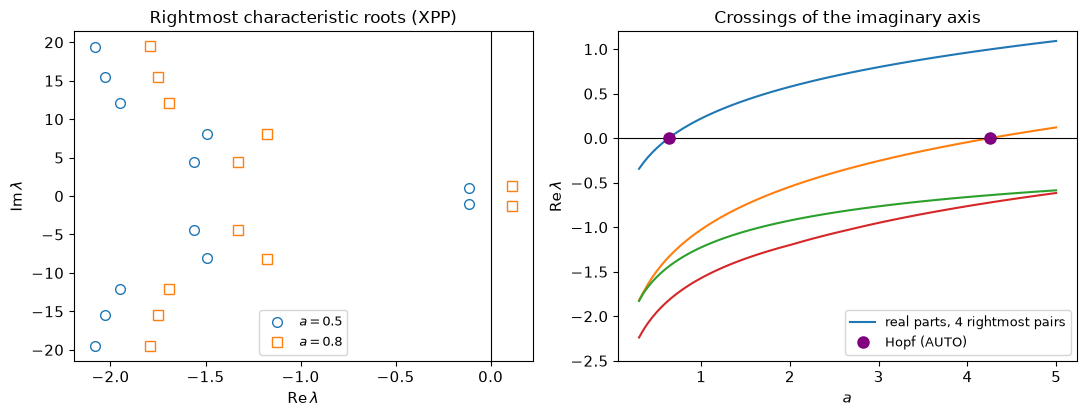

In [6]:
roots = {a: delay_roots(a) for a in (0.5, 0.8)}
print("characteristic roots at a = 0.8 (XPP, Sing pts):")
for z in roots[0.8][:6]:
    print(f"   {z.real:+.8f} {z.imag:+.8f} i    |residual| {abs(char(z, 0.8)):.1e}")
a_grid = np.linspace(0.3, 5, 95)
top = [delay_roots(a) for a in a_grid]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.3))
for a, mk in ((0.5, "o"), (0.8, "s")):
    a1.plot(roots[a].real, roots[a].imag, mk, mfc="none", ms=7, label=f"$a = {a}$")
a1.axvline(0, color="k", lw=0.8)
a1.set(xlabel=r"$\mathrm{Re}\,\lambda$", ylabel=r"$\mathrm{Im}\,\lambda$",
       title="Rightmost characteristic roots (XPP)")
a1.legend()
for k in range(4):
    a2.plot(a_grid, [np.sort(np.unique(np.round(r.real, 9)))[::-1][k] for r in top], "-", lw=1.5,
            label="real parts, 4 rightmost pairs" if k == 0 else None, color=f"C{k}")
a2.axhline(0, color="k", lw=0.8)
a2.plot([p.x for p in hbs], [0] * len(hbs), "o", color="purple", ms=8, label="Hopf (AUTO)")
a2.set(ylim=(-2.5, 1.2), xlabel="$a$", ylabel=r"$\mathrm{Re}\,\lambda$",
       title="Crossings of the imaginary axis")
a2.legend()
fig.tight_layout()
fig.savefig(FIG / "roots.png")

### Simulations on both sides of the first Hopf point

From the constant history $x = 0.1$, at $a = 0.5$ (stable) and $a = 0.8$
(unstable). After $t = 15$ the faster roots have died out, so the peaks grow
or decay like $e^{\mathrm{Re}\,\lambda\,t}$ and recur with frequency
$\mathrm{Im}\,\lambda$, where $\lambda$ is the rightmost root.

a = 0.5: peaks grow at rate -0.11124 with frequency 1.07589; rightmost root -0.11124 +- 1.07584 i


a = 0.8: peaks grow at rate +0.11192 with frequency 1.24349; rightmost root +0.11192 +- 1.24352 i


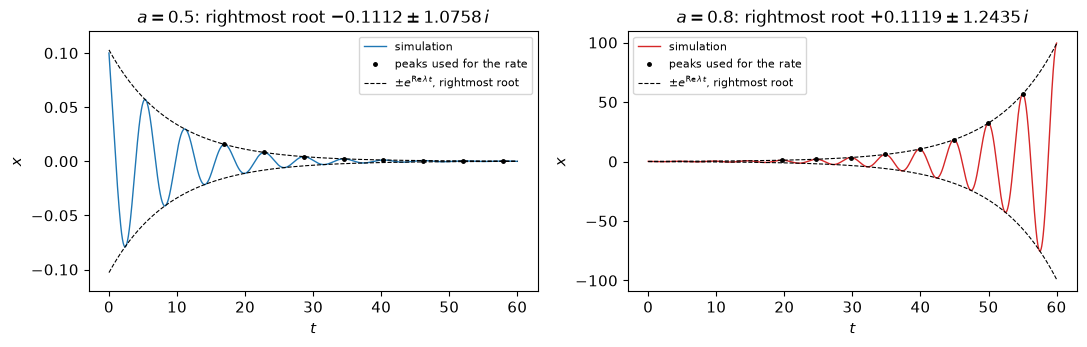

In [7]:
sims = {}
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (a, col) in zip(axs, ((0.5, "tab:blue"), (0.8, "tab:red"))):
    tr = m.run(keep=False, a=a, x=0.1, x0=0.1, total=60)
    t, x = tr.t, tr["x"]
    pk = np.where((x[1:-1] > x[:-2]) & (x[1:-1] >= x[2:]) & (x[1:-1] > 0))[0] + 1
    pk = pk[t[pk] > 15]
    rate = np.polyfit(t[pk], np.log(x[pk]), 1)[0]
    freq = 2 * np.pi / np.diff(t[pk]).mean()
    sims[a] = (rate, freq)
    lam = roots[a][0]
    env = x[pk[0]] * np.exp(lam.real * (t - t[pk[0]]))
    ax.plot(t, x, color=col, lw=1, label="simulation")
    ax.plot(t[pk], x[pk], "k.", ms=5, label="peaks used for the rate")
    ax.plot(t, env, "k--", lw=0.8, label=r"$\pm e^{\mathrm{Re}\,\lambda\,t}$, rightmost root")
    ax.plot(t, -env, "k--", lw=0.8)
    ax.set(xlabel="$t$", ylabel="$x$",
           title=rf"$a = {a}$: rightmost root ${lam.real:+.4f} \pm {lam.imag:.4f}\,i$")
    ax.legend(fontsize=8, loc="upper right" if a < 0.6 else "upper left")
    if a < 0.6:
        ax.set_ylim(-0.12, 0.12)
    print(f"a = {a}: peaks grow at rate {rate:+.5f} with frequency {freq:.5f}; "
          f"rightmost root {lam.real:+.5f} +- {lam.imag:.5f} i")
fig.tight_layout()
fig.savefig(FIG / "simulations.png")

### Checks

Put $\lambda = i\omega$ in the characteristic equation. The real part gives

$$
\cos\omega + \cos 1.7\omega = 2\cos(1.35\,\omega)\cos(0.35\,\omega) = 0,
$$

so $\omega = (2k+1)\pi/2.7$ or $\omega = (2k+1)\pi/0.7$, and the imaginary
part gives

$$
a = \frac{\omega}{\sin\omega + \sin 1.7\omega}.
$$

The Hopf points are the candidates with $0 < a < 5$; we check their number,
each $a$ and each $\omega = 2\pi/T$. At $a = 0.8$ three of XPP's roots are
compared with reference values (the rightmost is $0.11191770 + 1.24352376\,i$);
since XPP prints 10 significant digits, the characteristic function at a
printed root is about $10^{-9}|\lambda|$. `m.equilibrium` must return the
same rightmost root, and the simulated growth rates and frequencies must match
$\mathrm{Re}\,\lambda$ and $\mathrm{Im}\,\lambda$.

In [8]:
ws = np.sort(np.r_[(2 * np.arange(10) + 1) * np.pi / 2.7, (2 * np.arange(4) + 1) * np.pi / 0.7])
aa = ws / (np.sin(ws) + np.sin(1.7 * ws))
keep = (aa > 0) & (aa < 5)
check("number of Hopf points in 0 < a < 5", len(hbs), keep.sum(), 0)
for p, a_h, w_h in zip(hbs, aa[keep], ws[keep]):
    check(f"Hopf at a = {a_h:.6f} (exact)", p.x, a_h, 2e-6)
    check(f"  omega there = {w_h:.6f}", 2 * np.pi / p.period, w_h, 2e-5)
r8 = roots[0.8]
for ref in (0.11191770 + 1.24352376j, -1.33013388 + 4.45755707j, -1.17819739 + 8.12643108j):
    check(f"root at a = 0.8 near {ref:.4f}: distance", np.min(np.abs(r8 - ref)), 0, 1e-7)
check("the rightmost root at a = 0.8", r8[0].real, 0.11191770, 1e-8)
check("largest |characteristic function| / |lambda| at the 12 roots, a = 0.8",
      max(abs(char(z, 0.8)) / abs(z) for z in r8), 0, 1e-8)
m.set(a=0.8)
check("m.equilibrium's eigenvalue at a = 0.8 is the rightmost root",
      abs(m.equilibrium({"x": 0}).eigenvalues[0] - r8[0]), 0, 1e-7)
for a in (0.5, 0.8):
    check(f"a = {a}: growth rate of simulated peaks vs Re of rightmost root",
          sims[a][0], roots[a][0].real, 2e-3)
    check(f"a = {a}: simulated frequency vs Im of rightmost root", sims[a][1], roots[a][0].imag, 2e-3)
checks_done()

  ok   number of Hopf points in 0 < a < 5: 2 (expected 2)
  ok   Hopf at a = 0.633594 (exact): 0.633595 (expected 0.633594)
  ok     omega there = 1.163553: 1.16355 (expected 1.16355)
  ok   Hopf at a = 4.251022 (exact): 4.25102 (expected 4.25102)
  ok     omega there = 8.144870: 8.14487 (expected 8.14487)
  ok   root at a = 0.8 near 0.1119+1.2435j: distance: 3.64005e-09 (expected 0)
  ok   root at a = 0.8 near -1.3301+4.4576j: distance: 5.38517e-09 (expected 0)
  ok   root at a = 0.8 near -1.1782+8.1264j: distance: 5e-09 (expected 0)
  ok   the rightmost root at a = 0.8: 0.111918 (expected 0.111918)
  ok   largest |characteristic function| / |lambda| at the 12 roots, a = 0.8: 4.34591e-09 (expected 0)


  ok   m.equilibrium's eigenvalue at a = 0.8 is the rightmost root: 2.33062e-11 (expected 0)
  ok   a = 0.5: growth rate of simulated peaks vs Re of rightmost root: -0.111245 (expected -0.111239)
  ok   a = 0.5: simulated frequency vs Im of rightmost root: 1.07589 (expected 1.07584)
  ok   a = 0.8: growth rate of simulated peaks vs Re of rightmost root: 0.111917 (expected 0.111918)
  ok   a = 0.8: simulated frequency vs Im of rightmost root: 1.24349 (expected 1.24352)

32_two-delays: 15/15 checks passed


<a id="hutchinson-periodic-orbits"></a>
## 33. Hutchinson's delayed logistic equation: oscillations born in a Hopf point

$$
\dot x = r\,x(t)\,\bigl(1 - x(t-1)\bigr)
$$

A population whose growth is regulated by its size one generation ago. The
equilibrium $x = 1$ is stable for small $r$. Linearising there,
$u = x - 1$ obeys $\dot u = -r\,u(t-1)$, with the characteristic equation

$$
\lambda = -r\,e^{-\lambda}.
$$

At $r = \pi/2$ a pair of its roots crosses the imaginary axis at
$\lambda = i\pi/2$, and a periodic orbit of period 4 appears. Its amplitude
grows quickly with $r$, and for large $r$ the population spends long times
near 0.

We find the Hopf point with AUTO, continue the periodic orbits with XPP 8.2's
periodic-orbit solver for delay equations (with Floquet multipliers), import
one orbit into XPP, and compare amplitude and period along the branch with
long simulations.

In [9]:
section("33_hutchinson-periodic-orbits")

### The model

`delay=2`: XPP keeps two time units of the past. The history is the parameter
`x0`. The helper `simulate(r)` runs from the constant history $x = 1.2$ and
returns the maximum, the minimum and the period (from upward crossings of
$x = 1$) of the last 60 time units, and the run itself.

In [10]:
mb = (ModelBuilder("hutchinson")
      .comment("Hutchinson delayed logistic equation")
      .ode("x", "r*x*(1-delay(x,1))")
      .parameter(r=1.0, x0=1.0)
      .initial_value("x", "x0")
      .initial(x=1.0)
      .option(delay=2, meth="rk4", total=50, dt=0.01, maxstor=100000))
print(mb.render())
m = mb.load(ODE)


def simulate(r, total=400, keep_last=60):
    tr = m.run(keep=False, r=r, x=1.2, x0=1.2, total=total, trans=total - keep_last)
    t, x = tr.t, tr["x"]
    up = np.where((x[:-1] < 1) & (x[1:] >= 1))[0]
    tc = t[up] + (1 - x[up]) / (x[up + 1] - x[up]) * (t[up + 1] - t[up])
    return x.max(), x.min(), np.diff(tc).mean(), tr

# Hutchinson delayed logistic equation
x'=r*x*(1-delay(x,1))
par r=1.0,x0=1.0
x(0)=x0
init x=1.0
@ delay=2,meth=rungekutta,total=50,dt=0.01,maxstor=100000
done



### AUTO: the equilibrium $x = 1$ in $r$

At $r = 1$ the state $x = 1$ is already the equilibrium; AUTO starts from the
current state.

In [11]:
m.run(total=20)
m.run_last(total=1)
eqs = m.auto.run("r", start="steady", ds=0.01, dsmax=0.05, parmin=0.5, parmax=3, nmax=300)
hb = eqs.special("HB")[0]
print(f"Hopf point at r = {hb.x:.7f}, period {hb.period:.6f}; "
      f"rightmost root there {hb.eigenvalues[0]:.5f}")

Hopf point at r = 1.5707963, period 4.000000; rightmost root there 0.00000+1.57080j


### Periodic orbits from the Hopf point

`npr=5` labels every 5th orbit; only labelled orbits are kept for *Import* and
*Extend*. `p.multipliers[0]` is the largest nontrivial Floquet multiplier.

In [12]:
po = m.auto.run(grab=hb.label, choice="periodic", ds=0.01, dsmax=0.05, nmax=300, npr=5, parmax=3)
rs = np.array([p.x for p in po])
xmax = np.array([p.umax["x"] for p in po])
xmin = np.array([p.umin["x"] for p in po])
per = np.array([p.period for p in po])
stable = np.array([p.stable for p in po])
mult = np.array([abs(p.multipliers[0]) for p in po])
print(f"{len(po)} periodic orbits for r in [{rs[0]:.4f}, {rs[-1]:.3f}]; "
      f"stable at {stable.sum()} of them; largest |multiplier| {mult.max():.3f}")

62 periodic orbits for r in [1.5713, 3.000]; stable at 62 of them; largest |multiplier| 0.998


### One orbit from AUTO next to a simulation

Grab the labelled orbit nearest $r = 2$ and bring it into XPP's data with
*File → Import orbit*. Both curves are drawn from a peak; the AUTO orbit is
repeated once.

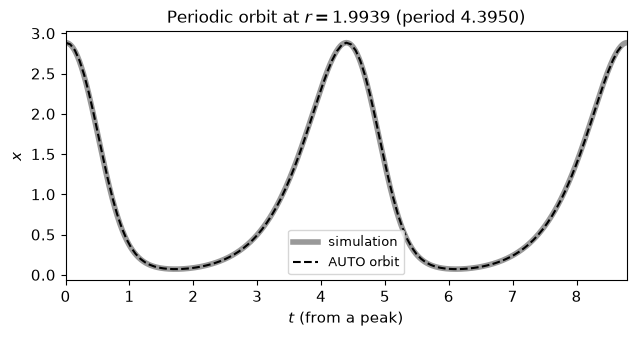

In [13]:
lab = min(po.labeled(), key=lambda p: abs(p.x - 2.0))
m.auto.grab(lab.label)
m.auto.buttons.file.import_orbit()
orb = m.data
smax, smin, sper, tr = simulate(lab.x)
fig, ax = plt.subplots(figsize=(6.5, 3.5))
i0 = np.argmax(tr["x"])
ts = tr.t[i0:] - tr.t[i0]
ax.plot(ts, tr["x"][i0:], color="0.6", lw=4, label="simulation")
j0 = np.argmax(orb["x"])
to = np.r_[orb.t[j0:] - orb.t[j0], orb.t[:j0] + orb.t[-1] - orb.t[j0]]
xo = np.r_[orb["x"][j0:], orb["x"][:j0]]
ax.plot(np.r_[to, to + lab.period], np.r_[xo, xo], "k--", lw=1.5, label="AUTO orbit")
ax.set(xlim=(0, 2 * lab.period), xlabel="$t$ (from a peak)", ylabel="$x$",
       title=f"Periodic orbit at $r = {lab.x:.4f}$ (period {lab.period:.4f})")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "orbit.png")

### Amplitude and period along the branch, against simulations

     r    max x: AUTO   sim     min x: AUTO   sim      period: AUTO   sim
  1.60      1.42287  1.42436      0.63969  0.63843      4.02041  4.02040
  1.80      2.29664  2.29853      0.19781  0.19725      4.18366  4.18353
  2.00      2.90146  2.90181      0.06890  0.06853      4.40291  4.40274
  2.30      3.87117  3.87138      0.00951  0.00947      4.89429  4.89414
  2.60      5.14979  5.15035      0.00056  0.00055      5.63527  5.63499
  2.90      6.87777  6.87957      0.00001  0.00001      6.65652  6.65626


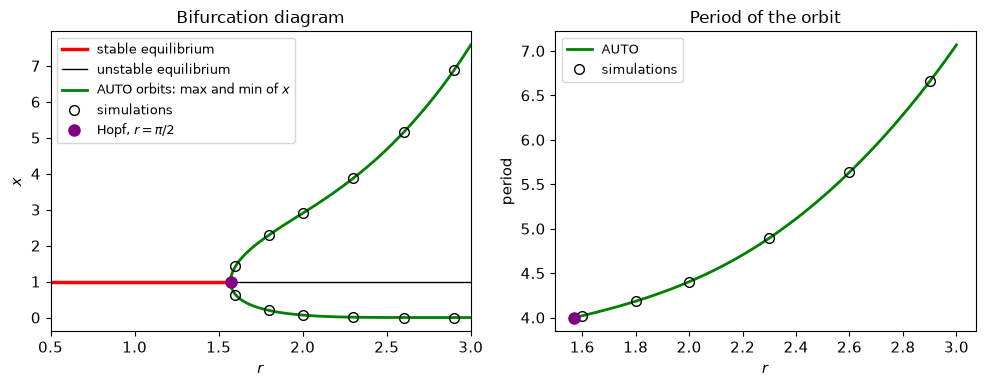

In [14]:
r_sim = np.array([1.6, 1.8, 2.0, 2.3, 2.6, 2.9])
sims = np.array([simulate(r)[:3] for r in r_sim])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))
a1.plot([0.5, hb.x], [1, 1], "r-", lw=2.5, label="stable equilibrium")
a1.plot([hb.x, 3], [1, 1], "k-", lw=1, label="unstable equilibrium")
a1.plot(rs, xmax, "g-", lw=2, label="AUTO orbits: max and min of $x$")
a1.plot(rs, xmin, "g-", lw=2)
a1.plot(r_sim, sims[:, 0], "ko", mfc="none", ms=7, label="simulations")
a1.plot(r_sim, sims[:, 1], "ko", mfc="none", ms=7)
a1.plot(hb.x, 1, "o", color="purple", ms=8, label=r"Hopf, $r = \pi/2$")
a1.set(xlim=(0.5, 3), xlabel="$r$", ylabel="$x$", title="Bifurcation diagram")
a1.legend(loc="upper left")
a2.plot(rs, per, "g-", lw=2, label="AUTO")
a2.plot(r_sim, sims[:, 2], "ko", mfc="none", ms=7, label="simulations")
a2.plot(hb.x, 4, "o", color="purple", ms=8)
a2.set(xlabel="$r$", ylabel="period", title="Period of the orbit")
a2.legend()
fig.tight_layout()
fig.savefig(FIG / "bifurcation.png")

print("     r    max x: AUTO   sim     min x: AUTO   sim      period: AUTO   sim")
for r, (sx, sn, sp) in zip(r_sim, sims):
    print(f"  {r:4.2f}   {np.interp(r, rs, xmax):10.5f} {sx:8.5f}   {np.interp(r, rs, xmin):10.5f} "
          f"{sn:8.5f}   {np.interp(r, rs, per):10.5f} {sp:8.5f}")

### Checks

* $\lambda = i\omega$ in $\lambda = -r e^{-\lambda}$ gives $r\cos\omega = 0$
  and $\omega = r\sin\omega$, so $\omega = r = \pi/2$ and the period at the
  Hopf point is $2\pi/\omega = 4$; the first orbit of the branch has period
  close to 4.
* With $y = x - 1$ the equation becomes Wright's equation
  $\dot y = -r\,y(t-1)\,(1 + y)$, whose (supercritical) Hopf orbit is
  $y \approx A\cos(\pi t/2)$ with

$$
A^2 = \frac{40\,(r - \pi/2)}{3\pi - 2}.
$$

* All orbits are stable (Floquet multipliers inside the unit circle).
* The imported orbit has the same maximum as AUTO's, and AUTO's maximum and
  period agree with the simulations (at $r \approx 2$, and to $0.5\%$ at all
  six values of $r$).

In [15]:
check("Hopf point r = pi/2 (exact)", hb.x, np.pi / 2, 1e-5)
check("period at the Hopf point = 4 (exact)", hb.period, 4.0, 1e-4)
check("first orbit of the branch has period near 4", per[0], 4.0, 1e-3)
amp0 = (xmax[0] - xmin[0]) / 2
check("amplitude near onset / Wright's law", amp0 / np.sqrt(40 * (rs[0] - np.pi / 2) / (3 * np.pi - 2)),
      1.0, 1e-2)
check("all orbits stable (Floquet multipliers inside the unit circle; 1 = yes)",
      float(stable.all()), 1, 0)
check("imported orbit: max x equals AUTO's", orb["x"].max(), lab.umax["x"], 1e-4)
check(f"max x at r = {lab.x:.3f}: AUTO vs simulation", lab.umax["x"], smax, 2e-3)
check(f"period at r = {lab.x:.3f}: AUTO vs simulation", lab.period, sper, 2e-3)
err_max = np.max(np.abs(np.interp(r_sim, rs, xmax) - sims[:, 0]) / sims[:, 0])
err_per = np.max(np.abs(np.interp(r_sim, rs, per) - sims[:, 2]) / sims[:, 2])
check("largest relative difference of max x, AUTO vs 6 simulations", err_max, 0, 5e-3)
check("largest relative difference of the period, AUTO vs 6 simulations", err_per, 0, 5e-3)
checks_done()

  ok   Hopf point r = pi/2 (exact): 1.5708 (expected 1.5708)
  ok   period at the Hopf point = 4 (exact): 4 (expected 4)
  ok   first orbit of the branch has period near 4: 4.00032 (expected 4)
  ok   amplitude near onset / Wright's law: 0.999736 (expected 1)
  ok   all orbits stable (Floquet multipliers inside the unit circle; 1 = yes): 1 (expected 1)
  ok   imported orbit: max x equals AUTO's: 2.88355 (expected 2.88355)
  ok   max x at r = 1.994: AUTO vs simulation: 2.88355 (expected 2.88384)
  ok   period at r = 1.994: AUTO vs simulation: 4.395 (expected 4.395)
  ok   largest relative difference of max x, AUTO vs 6 simulations: 0.00104683 (expected 0)
  ok   largest relative difference of the period, AUTO vs 6 simulations: 4.97715e-05 (expected 0)

33_hutchinson-periodic-orbits: 10/10 checks passed


<a id="cusp-delay"></a>
## 34. A cusp with a delay: folds of equilibria and delay-induced Hopf points

$$
\dot x = a + b\,x(t-1) - x(t-1)^3, \qquad b = 3 \text{ (at first)}.
$$

Without the delay this is the normal form of a cusp: three equilibria between
two folds, the outer two stable. The delay does not move the equilibria (they
still solve $a + bx - x^3 = 0$) or the folds, but it changes their stability.
The linearisation is $\dot u = c\,u(t-1)$ with $c = b - 3x^2$, with
characteristic equation

$$
\lambda = c\,e^{-\lambda};
$$

it loses stability when $c = -\pi/2$ (roots $\pm i\pi/2$, period 4), and a
second pair crosses at $c = -5\pi/2$ (roots $\pm 5i\pi/2$, period 0.8). So
the outer branches are stable only close to the folds.

We follow the equilibria in $a$ (two folds and four Hopf points), a fold in
$(a, b)$, and the periodic orbits born at the Hopf points: the period-4 orbit
grows until its period diverges (it ends on a loop through the middle
saddle); the period-0.8 orbits are unstable. Simulations confirm the
stability change on both sides of a Hopf point.

In [16]:
section("34_cusp-delay")

### The model

The history is the parameter `x0` (the delay is 1, so `delay=1` is enough).

In [17]:
mb = (ModelBuilder("cusp_delay")
      .comment("cusp normal form with a delayed argument")
      .ode("x", "a+b*delay(x,1)-delay(x,1)^3")
      .parameter(a=-3.0, b=3.0, x0=-2.1)
      .initial_value("x", "x0")
      .option(delay=1, meth="rk4", total=50, dt=0.01, bound=1000))
print(mb.render())
m = mb.load(ODE)
m.auto.parameters("a", "b")

# cusp normal form with a delayed argument
x'=a+b*delay(x,1)-delay(x,1)^3
par a=-3.0,b=3.0,x0=-2.1
x(0)=x0
@ delay=1,meth=rungekutta,total=50,dt=0.01,bound=1000
done



### Equilibria in $a$

At $a = -3$ the only equilibrium ($x = -2.104$) is unstable, so a simulation
would not find it: Newton's method does, and AUTO starts from the initial
conditions we set to it.

In [18]:
eq = m.equilibrium({"x": -2.1})
m.set(x=eq.x["X"], x0=eq.x["X"])
print(f"equilibrium at a = -3: x = {eq.x['X']:.6f}, rightmost root {eq.eigenvalues[0]:.4f}")
eqs = m.auto.run("a", start="steady", ds=0.01, dsmax=0.005, parmin=-3.5, parmax=3, nmax=3000)
lps, hbs = eqs.special("LP"), eqs.special("HB")
for p in lps + hbs:
    extra = f", period {p.period:.5f}" if p.type == "HB" else ""
    print(f"  {p.type} at a = {p.x:+.7f}, x = {p.u0['x']:+.6f}{extra}")

equilibrium at a = -3: x = -2.103803, rightmost root 1.3910+2.1459j


  LP at a = +2.0000000, x = -0.999996
  LP at a = -2.0000000, x = +0.999999
  HB at a = -1.1754881, x = -1.902103, period 0.80000
  HB at a = +1.8223775, x = -1.234344, period 3.99998
  HB at a = -1.8223733, x = +1.234347, period 3.99997
  HB at a = +1.1754881, x = +1.902103, period 0.80000


### The fold in $(a, b)$

Grab a fold and follow it in both directions in the *Two par* window. AUTO's
Newton tolerances `epsl`, `epsu` default to $10^{-4}$, which leaves an error
of $2\times 10^{-4}$ on this curve; $10^{-8}$ removes it. AUTO leaves the last
point's parameters behind, so we put $a$ and $b$ back.

In [19]:
m.auto.axes(plot="two_par", param="a", param2="b", xmin=-3.5, xmax=3.5, ymin=-0.5, ymax=5)
fold = [m.auto.run(grab=lps[0].label, ds=s * 0.01, dsmax=0.05, nmax=150, parmin=-3.5, parmax=3.5,
                   epsl=1e-8, epsu=1e-8) for s in (1, -1)]
fold_pts = [p for c in fold for p in c]
fa = np.array([p.x for p in fold_pts])
fb = np.array([p.par["b"] for p in fold_pts])
fx = np.array([p.u0["x"] for p in fold_pts])
m.set(a=-3.0, b=3.0)

<pyxpp.Model 34_cusp-delay.ode: vars=['X'] aux=[] pars=3>

### Periodic orbits from the Hopf points

The period of the period-4 orbit diverges near $a = -1.566$ (and $+1.566$ for
its mirror image); AUTO's mesh then grows to thousands of unknowns and each
step gets slow, so we stop after 45 steps there.

In [20]:
orbits = {}
for h in hbs:
    n = 45 if h.period > 2 else 60
    orbits[h.label] = m.auto.run(grab=h.label, choice="periodic", ds=0.01, dsmax=0.05, nmax=n,
                                 parmin=-3.5, parmax=3)
    o = orbits[h.label]
    print(f"  orbits from the Hopf point at a = {h.x:+.4f}: {len(o)} orbits up to a = {o[-1].x:+.4f}, "
          f"period {o[0].period:.3f} -> {o[-1].period:.3f}, stable at {sum(p.stable for p in o)}")

  orbits from the Hopf point at a = -1.1755: 52 orbits up to a = -3.5000, period 0.800 -> 0.812, stable at 0


  orbits from the Hopf point at a = +1.8224: 46 orbits up to a = +1.5658, period 4.011 -> 23.185, stable at 46


  orbits from the Hopf point at a = -1.8224: 47 orbits up to a = -1.5658, period 4.011 -> 23.185, stable at 47


  orbits from the Hopf point at a = +1.1755: 42 orbits up to a = +3.0000, period 0.800 -> 0.809, stable at 0


The bifurcation diagram for $b = 3$ (left) and the fold curve in $(a, b)$
against the exact curve $a = \pm(2b/3)\sqrt{b/3}$ (right).

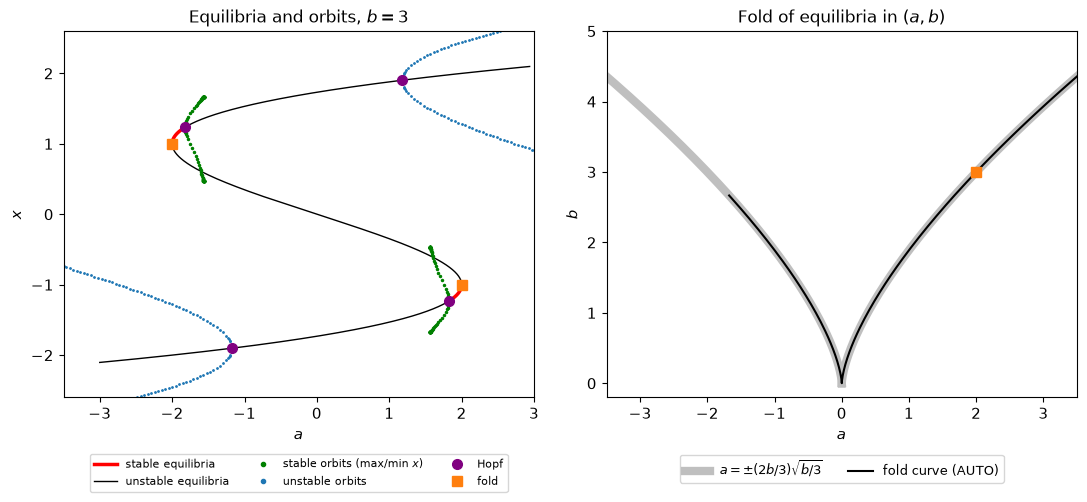

In [21]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 5.2))
xs = np.array([p.x for p in eqs])
us = np.array([p.u0["x"] for p in eqs])
st = np.array([p.stable for p in eqs])
a1.plot(xs, np.where(st, us, np.nan), "r-", lw=2.5, label="stable equilibria")
a1.plot(xs, np.where(~st, us, np.nan), "k-", lw=1, label="unstable equilibria")
for o in orbits.values():
    ox = np.array([p.x for p in o])
    ost = np.array([p.stable for p in o])
    for f in ("umax", "umin"):
        y = np.array([getattr(p, f)["x"] for p in o])
        a1.plot(ox[ost], y[ost], "g.", ms=3)
        a1.plot(ox[~ost], y[~ost], ".", color="tab:blue", ms=2)
a1.plot([], [], "g.", label="stable orbits (max/min $x$)")
a1.plot([], [], ".", color="tab:blue", label="unstable orbits")
a1.plot([p.x for p in hbs], [p.u0["x"] for p in hbs], "o", color="purple", ms=7, label="Hopf")
a1.plot([p.x for p in lps], [p.u0["x"] for p in lps], "s", color="tab:orange", ms=7, label="fold")
a1.set(xlim=(-3.5, 3), ylim=(-2.6, 2.6), xlabel="$a$", ylabel="$x$", title="Equilibria and orbits, $b = 3$")
a1.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)
bb = np.linspace(0, 5, 200)
a2.plot((2 * bb / 3) * np.sqrt(bb / 3), bb, color="0.75", lw=6, label=r"$a = \pm(2b/3)\sqrt{b/3}$")
a2.plot(-(2 * bb / 3) * np.sqrt(bb / 3), bb, color="0.75", lw=6)
for c in fold:
    a2.plot([p.x for p in c], [p.par["b"] for p in c], "k-", lw=1.5)
a2.plot([], [], "k-", label="fold curve (AUTO)")
a2.plot(lps[0].x, 3, "s", color="tab:orange", ms=7)
a2.set(xlim=(-3.5, 3.5), ylim=(-0.2, 5), xlabel="$a$", ylabel="$b$", title="Fold of equilibria in $(a, b)$")
a2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
fig.tight_layout()
fig.savefig(FIG / "bifurcation.png")

### Simulations on both sides of the Hopf point at $a = -1.8224$

Near the upper equilibrium (the largest root of $a + 3x - x^3 = 0$): at
$a = -1.9$ a small perturbation decays, at $a = -1.7$ it grows into the
period-4 oscillation.

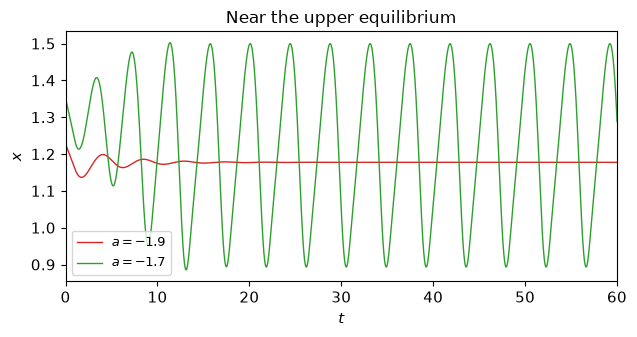

In [22]:
fig, ax = plt.subplots(figsize=(6.5, 3.5))
sim = {}
for a_val, col in ((-1.9, "tab:red"), (-1.7, "tab:green")):
    r = np.roots([-1, 0, 3, a_val])
    x_up = r.real[np.argmax(r.real)]
    tr = m.run(keep=False, a=a_val, x=x_up + 0.05, x0=x_up + 0.05, total=200)
    sim[a_val] = (tr, x_up)
    ax.plot(tr.t, tr["x"], color=col, lw=1, label=f"$a = {a_val}$")
ax.set(xlim=(0, 60), xlabel="$t$", ylabel="$x$", title="Near the upper equilibrium")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "simulations.png")

### Checks

* Folds: $a + bx - x^3 = 0$ and $b - 3x^2 = 0$ give $x^2 = b/3$ and
  $|a| = \frac{2b}{3}\sqrt{\frac{b}{3}}$. For $b = 3$ the folds are at
  $a = \pm 2$ ($x = \mp 1$), and every point of the fold curve (with
  $b \ge 0.05$) must satisfy both relations.
* Hopf points: $c = b - 3x^2 = -k\pi/2$ ($k = 1, 5$) gives roots
  $\pm ik\pi/2$ of $\lambda = c\,e^{-\lambda}$, with period $4/k$. With
  $b = 3$,

$$
x_{\mathrm{H}} = \pm\sqrt{\frac{3 + k\pi/2}{3}}, \qquad a_{\mathrm{H}} = x_{\mathrm{H}}^3 - 3x_{\mathrm{H}} .
$$

* The period-4 orbits from the Hopf point at $a = -1.822$ ($x = +1.234$) are
  stable and their period grows past 20 (they end on a saddle loop).
* At $a = -1.9$ the simulation settles on the equilibrium; at $a = -1.7$ the
  period of the simulated oscillation equals AUTO's (read off the branch up to
  its turning point near the saddle loop).

In [23]:
check("fold at a = +2 (x = -1)", max(p.x for p in lps), 2, 1e-6)
check("fold at a = -2 (x = +1)", min(p.x for p in lps), -2, 1e-6)
on = fb >= 0.05
err = np.max(np.abs(np.abs(fa[on]) - (2 * fb[on] / 3) * np.sqrt(fb[on] / 3)))
check(f"fold curve: largest | |a| - (2b/3) sqrt(b/3) | on {on.sum()} points", err, 0, 1e-6)
check("fold curve: largest | x^2 - b/3 |", np.max(np.abs(fx[on]**2 - fb[on] / 3)), 0, 1e-5)
for k, per in ((1, 4.0), (5, 0.8)):
    x_h = np.sqrt((3 + k * np.pi / 2) / 3)
    a_h = x_h**3 - 3 * x_h
    for sgn in (1, -1):
        h = min(hbs, key=lambda p: abs(p.x - sgn * a_h))
        check(f"Hopf at a = {sgn * a_h:+.6f} (x = {sgn * x_h:+.6f})", h.x, sgn * a_h, 2e-5)
        check("  period there", h.period, per, 1e-3 * per)
up = sorted(hbs, key=lambda p: p.x)[0]
o4 = orbits[up.label]
check("period-4 orbits are stable (1 = yes)", float(all(p.stable for p in o4)), 1, 0)
check("their period grows past 20 (end on a saddle loop)", float(o4[-1].period > 20), 1, 0)
tr, xu = sim[-1.9]
check("a = -1.9: simulation settles on the equilibrium", tr["x"][-1], xu, 1e-4)
tr, xu = sim[-1.7]
x = tr["x"][tr.t > 100]
t = tr.t[tr.t > 100]
upc = np.where((x[:-1] < xu) & (x[1:] >= xu))[0]
tc = t[upc] + (xu - x[upc]) / (x[upc + 1] - x[upc]) * (t[upc + 1] - t[upc])
T_sim = np.diff(tc).mean()
k4 = int(np.argmax([p.x for p in o4])) + 1
T_auto = np.interp(-1.7, [p.x for p in o4[:k4]], [p.period for p in o4[:k4]])
check("a = -1.7: period of the simulated oscillation vs AUTO", T_sim, T_auto, 1e-2)
checks_done()

  ok   fold at a = +2 (x = -1): 2 (expected 2)
  ok   fold at a = -2 (x = +1): -2 (expected -2)
  ok   fold curve: largest | |a| - (2b/3) sqrt(b/3) | on 189 points: 3.63438e-10 (expected 0)
  ok   fold curve: largest | x^2 - b/3 |: 8.9765e-06 (expected 0)
  ok   Hopf at a = -1.822383 (x = +1.234341): -1.82237 (expected -1.82238)
  ok     period there: 3.99997 (expected 4)
  ok   Hopf at a = +1.822383 (x = -1.234341): 1.82238 (expected 1.82238)
  ok     period there: 3.99998 (expected 4)
  ok   Hopf at a = +1.175488 (x = +1.902102): 1.17549 (expected 1.17549)
  ok     period there: 0.8 (expected 0.8)
  ok   Hopf at a = -1.175488 (x = -1.902102): -1.17549 (expected -1.17549)
  ok     period there: 0.8 (expected 0.8)
  ok   period-4 orbits are stable (1 = yes): 1 (expected 1)
  ok   their period grows past 20 (end on a saddle loop): 1 (expected 1)
  ok   a = -1.9: simulation settles on the equilibrium: 1.1774 (expected 1.1774)
  ok   a = -1.7: period of the simulated oscillation vs AUTO: 

<a id="marcus-westervelt"></a>
## 35. Two neurons with delayed coupling: a Hopf curve in (gain, delay)

$$
\dot x = -x + a\tanh\bigl(y(t-\tau)\bigr), \qquad \dot y = -y - a\tanh\bigl(x(t-\tau)\bigr),
$$

with $\tau = 1.3$ at first. Two model neurons excite and inhibit each other
through connections with a transmission delay $\tau$ (Marcus and Westervelt
studied such delayed networks). The rest state $(0, 0)$ has the characteristic
equation

$$
(\lambda + 1)^2 + a^2 e^{-2\lambda\tau} = 0 .
$$

For $\tau = 1.3$ a pair of roots crosses the imaginary axis at
$a = 1.235459$ and another at $a = 2.870196$, and a stable oscillation
appears at the first crossing.

We find both Hopf points, follow them in $(a, \tau)$ and check every point of
the curves against the characteristic equation, and compare the periodic
orbits from the first Hopf point with simulations.

In [24]:
section("35_marcus-westervelt")

### The model

The histories are the parameters `x0`, `y0`; `delay=3` covers delays up to 3.

`hopf_exact(tau, k)` gives the exact Hopf points: with $\lambda = i\omega$,
$1 + i\omega = \pm i a\,e^{-i\omega\tau}$, so

$$
a^2 = 1 + \omega^2, \qquad \arctan\omega + \omega\tau = \frac{\pi}{2} + k\pi,
$$

solved for $\omega$ by bisection.

In [25]:
mb = (ModelBuilder("marcus_westervelt")
      .comment("two neurons with delayed antisymmetric coupling")
      .ode("x", "-x+a*tanh(delay(y,tau))")
      .ode("y", "-y-a*tanh(delay(x,tau))")
      .parameter(a=0.5, tau=1.3, x0=0, y0=0)
      .initial_value("x", "x0")
      .initial_value("y", "y0")
      .initial(x=0, y=0)
      .option(delay=3, meth="rk4", total=100, dt=0.01, bound=1000))
print(mb.render())
m = mb.load(ODE)
m.auto.parameters("a", "tau")


def hopf_exact(tau, k):
    lo, hi = 0.0, 50.0
    for _ in range(100):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if np.arctan(mid) + mid * tau < np.pi / 2 + k * np.pi else (lo, mid)
    w = (lo + hi) / 2
    return np.sqrt(1 + w * w), w

# two neurons with delayed antisymmetric coupling
x'=-x+a*tanh(delay(y,tau))
y'=-y-a*tanh(delay(x,tau))
par a=0.5,tau=1.3,x0=0,y0=0
x(0)=x0
y(0)=y0
init x=0,y=0
@ delay=3,meth=rungekutta,total=100,dt=0.01,bound=1000
done



### The rest state in $a$, $\tau = 1.3$

In [26]:
m.run(total=1)
m.run_last(total=1)
eqs = m.auto.run("a", start="steady", ds=0.01, dsmax=0.002, parmin=0.3, parmax=3.5, nmax=3000)
hbs = eqs.special("HB")
for p in hbs:
    print(f"Hopf at a = {p.x:.6f}, omega = {2 * np.pi / p.period:.6f}")

Hopf at a = 1.235459, omega = 0.725505
Hopf at a = 2.870196, omega = 2.690358


### Hopf curves in $(a, \tau)$

Each Hopf point is followed in both directions (`choice="two param"`) with
tight Newton tolerances (the default $10^{-4}$ leaves errors of about
$10^{-3}$), keeping $\tau \le 6$. At every point we evaluate the
characteristic equation at $\lambda = i\omega$, $\omega = 2\pi/T$, relative
to $1 + \omega^2$, and the relation $\omega = \sqrt{a^2 - 1}$.

In [27]:
curves = []
for h in hbs:
    for s in (1, -1):
        c = m.auto.run(grab=h.label, choice="two param", ds=s * 0.01, dsmax=0.05, nmax=200,
                       parmin=0.3, parmax=3.5, epsl=1e-8, epsu=1e-8)
        curves.append([p for p in c if p.par["tau"] <= 6])
res, wres = [], []
for c in curves:
    for p in c:
        a, tau, w = p.x, p.par["tau"], 2 * np.pi / p.period
        res.append(abs((1j * w + 1)**2 + a * a * np.exp(-2j * w * tau)) / (1 + w * w))
        wres.append(abs(w - np.sqrt(a * a - 1)))
npts = sum(len(c) for c in curves)
print(f"Hopf curves: {npts} points")
m.set(a=0.5, tau=1.3)

Hopf curves: 329 points


<pyxpp.Model 35_marcus-westervelt.ode: vars=['X', 'Y'] aux=[] pars=4>

### Periodic orbits from the first Hopf point, and simulations

Simulations at $a = 1.4$, $1.8$, $2.4$ give the maximum of $x$ and the period
(from upward zero crossings) after a transient of 200.

59 periodic orbits, stable at 59


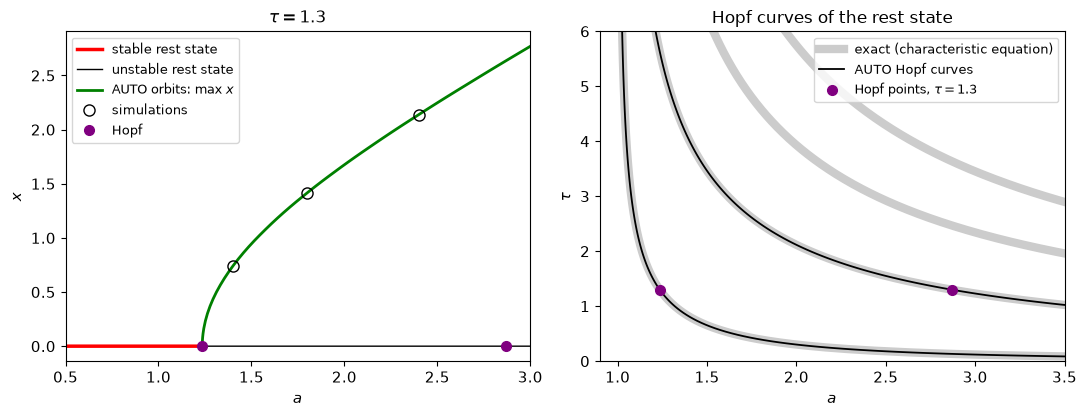

In [28]:
po = m.auto.run(grab=hbs[0].label, choice="periodic", ds=0.01, dsmax=0.05, nmax=200, parmax=3.0)
pa = np.array([p.x for p in po])
pmax = np.array([p.umax["x"] for p in po])
pper = np.array([p.period for p in po])
print(f"{len(po)} periodic orbits, stable at {sum(p.stable for p in po)}")
a_sim = np.array([1.4, 1.8, 2.4])
sims = []
for a in a_sim:
    tr = m.run(keep=False, a=a, tau=1.3, x=0.1, x0=0.1, y=0, y0=0, total=300, trans=200)
    t, x = tr.t, tr["x"]
    up = np.where((x[:-1] < 0) & (x[1:] >= 0))[0]
    tc = t[up] - x[up] / (x[up + 1] - x[up]) * (t[up + 1] - t[up])
    sims.append((x.max(), np.diff(tc).mean()))
sims = np.array(sims)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.3))
tt = np.linspace(0.01, 6, 400)
for k in range(4):
    pts = np.array([hopf_exact(t_, k) for t_ in tt])
    a2.plot(pts[:, 0], tt, color="0.8", lw=6, label="exact (characteristic equation)" if k == 0 else None)
for i, c in enumerate(curves):
    a2.plot([p.x for p in c], [p.par["tau"] for p in c], "k-", lw=1.3,
            label="AUTO Hopf curves" if i == 0 else None)
a2.plot([p.x for p in hbs], [1.3, 1.3], "o", color="purple", ms=7, label=r"Hopf points, $\tau = 1.3$")
a2.set(xlim=(0.9, 3.5), ylim=(0, 6), xlabel="$a$", ylabel=r"$\tau$", title="Hopf curves of the rest state")
a2.legend(loc="upper right")
st = np.array([p.stable for p in eqs])
xs = np.array([p.x for p in eqs])
a1.plot(xs, np.where(st, 0, np.nan), "r-", lw=2.5, label="stable rest state")
a1.plot(xs, np.where(~st, 0, np.nan), "k-", lw=1, label="unstable rest state")
a1.plot(pa, pmax, "g-", lw=2, label="AUTO orbits: max $x$")
a1.plot(a_sim, sims[:, 0], "ko", mfc="none", ms=8, label="simulations")
a1.plot([p.x for p in hbs], [0, 0], "o", color="purple", ms=7, label="Hopf")
a1.set(xlim=(0.5, 3.0), xlabel="$a$", ylabel="$x$", title=r"$\tau = 1.3$")
a1.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "bifurcation.png")

### Checks

* Both Hopf points at $\tau = 1.3$ and their frequencies against
  `hopf_exact` ($k = 0$: $a = 1.235459$, $\omega = 0.725505$; $k = 1$:
  $a = 2.870196$, $\omega = 2.690358$).
* On every point of the Hopf curves,
  $\bigl|(i\omega + 1)^2 + a^2 e^{-2i\omega\tau}\bigr| / (1 + \omega^2)$ and
  $\bigl|\omega - \sqrt{a^2 - 1}\bigr|$ are below $10^{-4}$.
* The orbits from the first Hopf point are stable, and their maximum and
  period agree with the simulations.

In [29]:
for p, (k, a_ref, w_ref) in zip(hbs, ((0, 1.235459, 0.725505), (1, 2.870196, 2.690358))):
    a_ex, w_ex = hopf_exact(1.3, k)
    check(f"Hopf at a = {a_ref} (exact {a_ex:.7f})", p.x, a_ex, 2e-5)
    check(f"  omega there ({w_ref})", 2 * np.pi / p.period, w_ex, 2e-5)
check(f"Hopf curves: largest |(iw+1)^2 + a^2 exp(-2iw tau)| / (1+w^2) on {npts} points",
      max(res), 0, 1e-4)
check("Hopf curves: largest |w - sqrt(a^2 - 1)|", max(wres), 0, 1e-4)
check("orbits from the first Hopf point are stable (1 = yes)", float(all(p.stable for p in po)), 1, 0)
for a, (smax, sper) in zip(a_sim, sims):
    check(f"a = {a}: max x, AUTO vs simulation", np.interp(a, pa, pmax), smax, 2e-3)
    check(f"a = {a}: period, AUTO vs simulation", np.interp(a, pa, pper), sper, 2e-3)
checks_done()

  ok   Hopf at a = 1.235459 (exact 1.2354586): 1.23546 (expected 1.23546)
  ok     omega there (0.725505): 0.725505 (expected 0.725505)
  ok   Hopf at a = 2.870196 (exact 2.8701960): 2.8702 (expected 2.8702)
  ok     omega there (2.690358): 2.69036 (expected 2.69036)
  ok   Hopf curves: largest |(iw+1)^2 + a^2 exp(-2iw tau)| / (1+w^2) on 329 points: 4.30932e-07 (expected 0)
  ok   Hopf curves: largest |w - sqrt(a^2 - 1)|: 4.40483e-07 (expected 0)
  ok   orbits from the first Hopf point are stable (1 = yes): 1 (expected 1)
  ok   a = 1.4: max x, AUTO vs simulation: 0.739411 (expected 0.739797)
  ok   a = 1.4: period, AUTO vs simulation: 8.64063 (expected 8.64066)
  ok   a = 1.8: max x, AUTO vs simulation: 1.41585 (expected 1.41615)
  ok   a = 1.8: period, AUTO vs simulation: 8.52261 (expected 8.5226)
  ok   a = 2.4: max x, AUTO vs simulation: 2.13819 (expected 2.13868)
  ok   a = 2.4: period, AUTO vs simulation: 8.35221 (expected 8.3522)

35_marcus-westervelt: 13/13 checks passed


<a id="wilson-cowan-delay"></a>
## 36. Wilson–Cowan with a delay: an excitatory–inhibitory pair starts to oscillate

$$
\dot E = -E + S\bigl(6E - 8\,I(t-\tau) + P\bigr), \qquad
0.5\,\dot I = -I + S\bigl(8\,E(t-\tau) - I + Q\bigr), \qquad
S(u) = \frac{1}{1 + e^{-u}},
$$

with $Q = 0$ and first $\tau = 1$. An excitatory and an inhibitory population
reach each other only after a delay $\tau$. There is one equilibrium for every
input $P$ in $[-1, 4]$. With $\tau = 1$ it loses stability at
$P = 1.54359$, where a pair of characteristic roots crosses at
$\pm 0.87492\,i$, and a stable rhythm appears. Shorter delays need a stronger
input: the Hopf curve in $(P, \tau)$ bends to larger $P$ as $\tau$ falls.

We find the Hopf point, follow it in $(P, \tau)$ and check every point against
the characteristic equation and the curve against four verified points, and
compare the periodic orbits with simulations on both sides of the Hopf point.

In [30]:
section("36_wilson-cowan-delay")

### The model

The histories are the parameters `e0`, `i0`, set to the equilibrium at
$P = 0$.

`char_det` measures how well a point satisfies the characteristic equation.
Linearising at $(E, I)$ with $g_1 = S'(6E - 8I + P)$, $g_2 = S'(8E - I + Q)$
and $S' = S(1 - S)$ gives the characteristic matrix

$$
\Delta(\lambda) = \begin{pmatrix} \lambda + 1 - 6g_1 & 8g_1 e^{-\lambda\tau} \\ -16g_2 e^{-\lambda\tau} & \lambda + 2 + 2g_2 \end{pmatrix},
$$

$$
\det\Delta(\lambda) = (\lambda + 1 - 6g_1)(\lambda + 2 + 2g_2) + 128\,g_1g_2\,e^{-2\lambda\tau},
$$

and the function returns $|\det\Delta(i\omega)|$ relative to the size of its
two terms.

In [31]:
mb = (ModelBuilder("wilson_cowan_delay")
      .comment("Wilson-Cowan E-I pair with delayed E<->I interaction")
      .function("s(u)", "1/(1+exp(-u))")
      .ode("E", "-E+s(6*E-8*delay(I,tau)+P)")
      .ode("I", "(-I+s(8*delay(E,tau)-I+Q))/0.5")
      .parameter(P=0.0, Q=0.0, tau=1.0, e0=0.031767, i0=0.450954)
      .initial_value("E", "e0")
      .initial_value("I", "i0")
      .initial(E=0.031767, I=0.450954)
      .option(delay=2, meth="rk4", total=200, dt=0.01, bound=1000))
print(mb.render())
m = mb.load(ODE)
m.auto.parameters("P", "Q", "tau")


def char_det(P, Q, E, I, tau, w):
    s = lambda u: 1 / (1 + np.exp(-u))
    g1 = s(6 * E - 8 * I + P) * (1 - s(6 * E - 8 * I + P))
    g2 = s(8 * E - I + Q) * (1 - s(8 * E - I + Q))
    l, z = 1j * w, np.exp(-2j * w * tau)
    d1, d2 = l + 1 - 6 * g1, l + 2 + 2 * g2
    return abs(d1 * d2 + 128 * g1 * g2 * z) / (abs(d1 * d2) + 128 * g1 * g2)

# Wilson-Cowan E-I pair with delayed E<->I interaction
s(u)=1/(1+exp(-u))
E'=-E+s(6*E-8*delay(I,tau)+P)
I'=(-I+s(8*delay(E,tau)-I+Q))/0.5
par P=0.0,Q=0.0,tau=1.0,e0=0.031767,i0=0.450954
E(0)=e0
I(0)=i0
init E=0.031767,I=0.450954
@ delay=2,meth=rungekutta,total=200,dt=0.01,bound=1000
done



### The equilibrium in $P$, $\tau = 1$

In [32]:
m.run(total=1)
m.run_last(total=1)
eqs = m.auto.run("P", start="steady", ds=0.01, dsmax=0.005, parmin=-1, parmax=4, nmax=3000)
hb = eqs.special("HB")[0]
print(f"Hopf at P = {hb.x:.6f}, omega = {2 * np.pi / hb.period:.6f}")

Hopf at P = 1.543593, omega = 0.874915


### The Hopf curve in $(P, \tau)$

Tight Newton tolerances (the default $10^{-4}$ is too loose for these checks),
and `dsmax=0.01` upwards so that the points lie close enough together to read
$\tau$ and $\omega$ off the curve by interpolation.

In [33]:
up = m.auto.run(grab=hb.label, choice="two param", param2="tau", ds=0.01, dsmax=0.01, nmax=400,
                epsl=1e-8, epsu=1e-8, parmin=-1, parmax=4)
dn = m.auto.run(grab=hb.label, choice="two param", param2="tau", ds=-0.01, dsmax=0.05, nmax=120,
                epsl=1e-8, epsu=1e-8, parmin=-1, parmax=4)
curve = sorted(list(up) + list(dn), key=lambda p: p.par["tau"])
cP = np.array([p.x for p in curve])
ctau = np.array([p.par["tau"] for p in curve])
cw = np.array([2 * np.pi / p.period for p in curve])
res = [char_det(p.x, 0, p.u0["E"], p.u0["I"], p.par["tau"], 2 * np.pi / p.period) for p in curve]
print(f"Hopf curve: {len(curve)} points, tau from {ctau.min():.3f} to {ctau.max():.2f}")
m.set(P=0.0, tau=1.0)

Hopf curve: 396 points, tau from 0.297 to 5.53


<pyxpp.Model 36_wilson-cowan-delay.ode: vars=['E', 'I'] aux=[] pars=5>

### Periodic orbits and simulations

Simulations at $P = 1.3$ (below the Hopf point), $2.0$ and $3.0$: maximum,
minimum and period of $E$ after a transient of 250.

56 periodic orbits from P = 1.5590, stable at 56


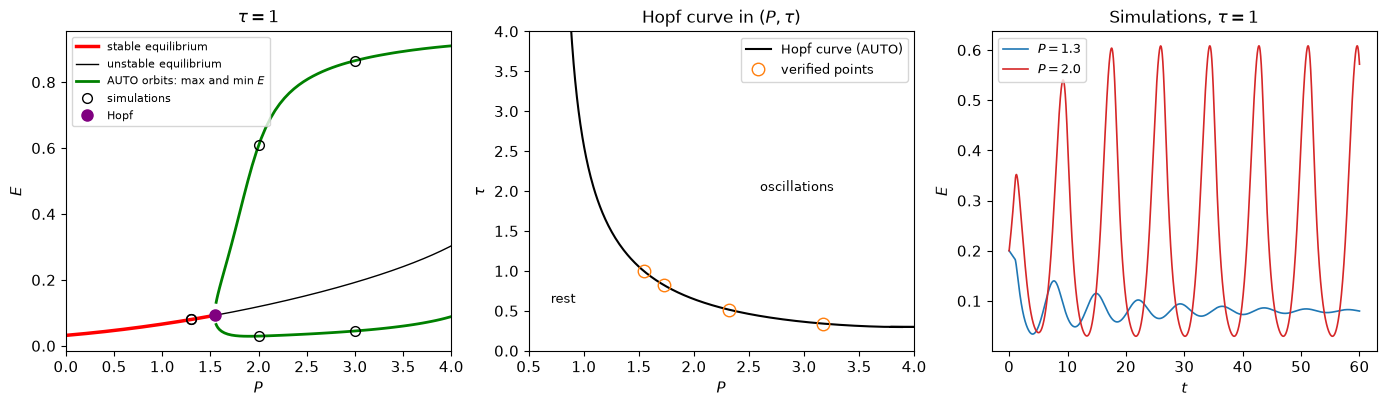

In [34]:
po = m.auto.run(grab=hb.label, choice="periodic", ds=0.01, dsmax=0.05, nmax=200, parmin=-1, parmax=4)
pP = np.array([p.x for p in po])
pmax = np.array([p.umax["E"] for p in po])
pmin = np.array([p.umin["E"] for p in po])
pper = np.array([p.period for p in po])
print(f"{len(po)} periodic orbits from P = {pP[0]:.4f}, stable at {sum(p.stable for p in po)}")
sims = {}
for P in (1.3, 2.0, 3.0):
    tr = m.run(keep=False, P=P, tau=1.0, E=0.2, e0=0.2, I=0.5, i0=0.5, total=400, trans=250)
    t, e = tr.t, tr["E"]
    lev = 0.5 * (e.max() + e.min())
    upc = np.where((e[:-1] < lev) & (e[1:] >= lev))[0]
    tc = t[upc] + (lev - e[upc]) / (e[upc + 1] - e[upc]) * (t[upc + 1] - t[upc])
    sims[P] = (tr, e.max(), e.min(), np.diff(tc).mean() if len(tc) > 2 else np.nan)

fig, axs = plt.subplots(1, 3, figsize=(14, 4.2))
xs = np.array([p.x for p in eqs])
st = np.array([p.stable for p in eqs])
ee = np.array([p.u0["E"] for p in eqs])
axs[0].plot(xs, np.where(st, ee, np.nan), "r-", lw=2.5, label="stable equilibrium")
axs[0].plot(xs, np.where(~st, ee, np.nan), "k-", lw=1, label="unstable equilibrium")
axs[0].plot(pP, pmax, "g-", lw=2, label="AUTO orbits: max and min $E$")
axs[0].plot(pP, pmin, "g-", lw=2)
for P, (tr, smx, smn, _) in sims.items():
    axs[0].plot([P, P], [smx, smn], "ko", mfc="none", ms=7, label="simulations" if P == 1.3 else None)
axs[0].plot(hb.x, hb.u0["E"], "o", color="purple", ms=8, label="Hopf")
axs[0].set(xlim=(0, 4), xlabel="$P$", ylabel="$E$", title=r"$\tau = 1$")
axs[0].legend(fontsize=8, loc="upper left")
axs[1].plot(cP, ctau, "k-", lw=1.5, label="Hopf curve (AUTO)")
ref = np.array([(1.5436, 1.0000, 0.8749), (1.7306, 0.8200, 0.9869), (2.3153, 0.5157, 1.2717),
                (3.1739, 0.3400, 1.5005)])
axs[1].plot(ref[:, 0], ref[:, 1], "o", color="tab:orange", mfc="none", ms=9, label="verified points")
axs[1].set(xlim=(0.5, 4), ylim=(0, 4), xlabel="$P$", ylabel=r"$\tau$", title=r"Hopf curve in $(P, \tau)$")
axs[1].text(2.6, 2.0, "oscillations", fontsize=9)
axs[1].text(0.7, 0.6, "rest", fontsize=9)
axs[1].legend()
for P, col in ((1.3, "tab:blue"), (2.0, "tab:red")):
    tr = m.run(keep=False, P=P, tau=1.0, E=0.2, e0=0.2, I=0.5, i0=0.5, total=60)
    axs[2].plot(tr.t, tr["E"], color=col, lw=1.2, label=f"$P = {P}$")
axs[2].set(xlabel="$t$", ylabel="$E$", title=r"Simulations, $\tau = 1$")
axs[2].legend()
fig.tight_layout()
fig.savefig(FIG / "bifurcation.png")

### Checks

* The Hopf point at $\tau = 1$: $P = 1.54359$, $\omega = 0.87492$, and
  $\det\Delta(i\omega) = 0$ there (relative to its terms, below $10^{-5}$).
* $\det\Delta(i\omega) = 0$ at every point of the Hopf curve.
* The curve against three verified points $(P, \tau, \omega)$ =
  $(1.7306, 0.8200, 0.9869)$, $(2.3153, 0.5157, 1.2717)$,
  $(3.1739, 0.3400, 1.5005)$. They are rounded to 4 decimals, so we read
  $\tau$ and $\omega$ off the curve at the listed $P$ (where the curve is steep
  in $P$, $\tau$ changes slowly with $P$: the well-conditioned direction).
* The orbits are stable; at $P = 1.3$ the simulation settles; at $P = 2$ and
  $3$ AUTO's maximum and period agree with the simulations.

In [35]:
check("Hopf point P at tau = 1", hb.x, 1.54359, 2e-5)
check("  omega there", 2 * np.pi / hb.period, 0.87492, 2e-5)
check("  |det Delta(i omega)| there (relative)", char_det(hb.x, 0, hb.u0["E"], hb.u0["I"], 1, 2 * np.pi / hb.period), 0, 1e-5)
check(f"Hopf curve: largest relative |det Delta(i omega)| on {len(curve)} points", max(res), 0, 1e-5)
o = np.argsort(cP)
for P_r, tau_r, w_r in ref[1:]:
    check(f"curve at P = {P_r}: tau", np.interp(P_r, cP[o], ctau[o]), tau_r, 1e-4)
    check(f"curve at P = {P_r}: omega", np.interp(P_r, cP[o], cw[o]), w_r, 1e-4)
check("orbits stable (1 = yes)", float(all(p.stable for p in po)), 1, 0)
check("P = 1.3: simulation settles (max - min of E)", sims[1.3][1] - sims[1.3][2], 0, 1e-5)
for P in (2.0, 3.0):
    _, smx, smn, sper = sims[P]
    check(f"P = {P}: max E, AUTO vs simulation", np.interp(P, pP, pmax), smx, 2e-3)
    check(f"P = {P}: period, AUTO vs simulation", np.interp(P, pP, pper), sper, 1e-2)
checks_done()

  ok   Hopf point P at tau = 1: 1.54359 (expected 1.54359)
  ok     omega there: 0.874915 (expected 0.87492)
  ok     |det Delta(i omega)| there (relative): 2.2578e-07 (expected 0)
  ok   Hopf curve: largest relative |det Delta(i omega)| on 396 points: 2.31128e-07 (expected 0)
  ok   curve at P = 1.7306: tau: 0.81998 (expected 0.82)
  ok   curve at P = 1.7306: omega: 0.986942 (expected 0.9869)
  ok   curve at P = 2.3153: tau: 0.515688 (expected 0.5157)
  ok   curve at P = 2.3153: omega: 1.27166 (expected 1.2717)
  ok   curve at P = 3.1739: tau: 0.340038 (expected 0.34)
  ok   curve at P = 3.1739: omega: 1.50053 (expected 1.5005)
  ok   orbits stable (1 = yes): 1 (expected 1)
  ok   P = 1.3: simulation settles (max - min of E): 1.11759e-07 (expected 0)
  ok   P = 2.0: max E, AUTO vs simulation: 0.607615 (expected 0.608351)
  ok   P = 2.0: period, AUTO vs simulation: 8.4106 (expected 8.41299)
  ok   P = 3.0: max E, AUTO vs simulation: 0.864979 (expected 0.865094)
  ok   P = 3.0: period, 

<a id="mackey-glass-period-doubling"></a>
## 37. Mackey–Glass: a period-doubling cascade in a delay equation

$$
\dot x = \frac{\beta\,x(t-\tau)}{1 + x(t-\tau)^{10}} - \gamma\,x,
$$

with $\tau = 2$, $\gamma = 1$. A model of blood-cell production with a
maturation delay $\tau$. The equilibrium $x^* = (\beta - 1)^{1/10}$ loses
stability in a Hopf point at $\beta = 1.3369$; the periodic orbit born there
period-doubles at $\beta = 1.5554491$, the doubled orbit again at
$1.6958309$, and again at $1.7199016$, on the way to chaos.

We find the Hopf points, continue the periodic orbits (XPP 8.2 computes their
Floquet multipliers and locates the period doublings, PD), switch branch at
each PD to follow the orbits of period 2, 4 and 8 times the first, follow the
first PD in $(\beta, \tau)$, and compare everything with an orbit diagram from
simulations.

In [36]:
section("37_mackey-glass-period-doubling")

### The model

The history is the parameter `x0`, here the equilibrium
$(\beta - 1)^{1/10} = 0.827197$ at $\beta = 1.15$. $\tau$ must be in AUTO's
parameter list for the two-parameter step.

In [37]:
mb = (ModelBuilder("mackey_glass")
      .comment("Mackey-Glass equation")
      .ode("x", "beta*delay(x,tau)/(1+delay(x,tau)^10)-gamma*x")
      .parameter(beta=1.15, tau=2, gamma=1, x0=0.827197)
      .initial_value("x", "x0")
      .initial(x=0.827197)
      .option(delay=3, meth="rk4", total=100, dt=0.01, maxstor=100000))
print(mb.render())
m = mb.load(ODE)
m.auto.parameters("beta", "tau", "gamma")

# Mackey-Glass equation
x'=beta*delay(x,tau)/(1+delay(x,tau)^10)-gamma*x
par beta=1.15,tau=2,gamma=1,x0=0.827197
x(0)=x0
init x=0.827197
@ delay=3,meth=rungekutta,total=100,dt=0.01,maxstor=100000
done



### Equilibria in $\beta$

In [38]:
m.run(total=100)
m.run_last(total=1)
eqs = m.auto.run("beta", start="steady", ds=0.01, dsmax=0.05, parmin=1, parmax=2.2, nmax=300)
hb = eqs.special("HB")
print("Hopf points: beta =", [round(p.x, 6) for p in hb])

Hopf points: beta = [1.336856, 2.070293]


### Periodic orbits and the period-doubling cascade

From the first Hopf point, then at each PD `choice="doubling"` switches to the
doubled branch. At a PD one Floquet multiplier is $-1$.

In [39]:
branches, pds = [], []
br = m.auto.run(grab=hb[0].label, choice="periodic", ds=0.01, dsmax=0.02, nmax=300, parmax=2.2)
branches.append(br)
for k in range(3):
    pd = br.special("PD")[0]
    pds.append(pd)
    print(f"  PD on the period-{2**k} branch at beta = {pd.x:.7f} (period {pd.period:.5f}, "
          f"multiplier {pd.multipliers[0].real:+.6f})")
    if k < 2:
        br = m.auto.run(grab=pd.label, choice="doubling", ds=0.005, dsmax=0.01, nmax=300,
                        parmax=1.8)
        branches.append(br)
br8 = m.auto.run(grab=pds[2].label, choice="doubling", ds=0.002, dsmax=0.004, nmax=60, parmax=1.73)
branches.append(br8)
print(f"  period-8 orbits from beta = {br8[0].x:.5f} (period {br8[0].period:.4f})")

  PD on the period-1 branch at beta = 1.5554491 (period 5.50622, multiplier -1.000000)


  PD on the period-2 branch at beta = 1.6958309 (period 11.86742, multiplier -1.000000)


  PD on the period-4 branch at beta = 1.7199016 (period 23.59419, multiplier -1.000000)


  period-8 orbits from beta = 1.72032 (period 47.1868)


### The first PD in the $(\beta, \tau)$ plane

The curve is followed inside the *Two par* window; ending it at the window's
edge $\beta = 2$ gives $\tau$ there. The Hopf curve of the equilibrium is
drawn too. AUTO leaves the last point's parameters behind, so $\tau$ is put
back to 2.

  parameters after the two-parameter runs: {'beta': 1.2604, 'tau': 7.5449}
  PD curve: from (beta, tau) = (1.5097, 2.3000) to (2.0000, 1.324922)


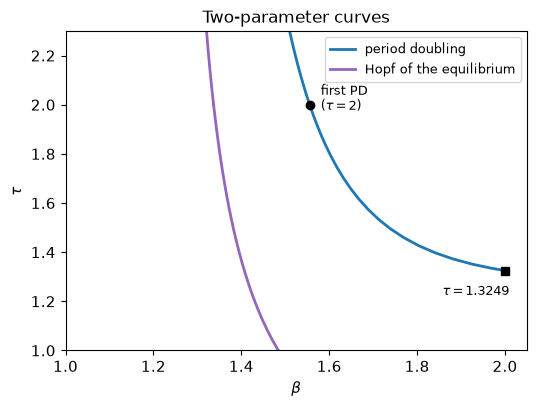

In [40]:
m.auto.axes(plot="two_par", param="beta", param2="tau", xmin=1.3, xmax=2.0, ymin=1.0, ymax=2.3)
pd_up = m.auto.run(grab=pds[0].label, choice="two param", ds=0.01, dsmax=0.05, nmax=200)
pd_dn = m.auto.run(grab=pds[0].label, choice="two param", ds=-0.01, dsmax=0.05, nmax=200)
hb_curve = [m.auto.run(grab=hb[0].label, choice="two param", ds=s * 0.01, dsmax=0.05, nmax=120,
                       parmax=2.0) for s in (1, -1)]
tau_at_2 = pd_up[-1].par["tau"]
print("  parameters after the two-parameter runs:", {k: round(m.get(k), 4) for k in ("beta", "tau")})
m.set(tau=2.0)
print(f"  PD curve: from (beta, tau) = ({pd_dn[-1].x:.4f}, {pd_dn[-1].par['tau']:.4f}) "
      f"to ({pd_up[-1].x:.4f}, {tau_at_2:.6f})")

fig, ax = plt.subplots(figsize=(5.5, 4.2))
for c, col, lab in ((pd_up, "tab:blue", "period doubling"), (pd_dn, "tab:blue", None),
                    (hb_curve[0], "tab:purple", "Hopf of the equilibrium"), (hb_curve[1], "tab:purple", None)):
    ax.plot([p.x for p in c], [p.par["tau"] for p in c], "-", color=col, lw=2, label=lab)
ax.plot(pds[0].x, 2, "ko", ms=6)
ax.plot(2.0, tau_at_2, "ks", ms=6)
ax.annotate("first PD\n" + r"($\tau = 2$)", (pds[0].x, 2), xytext=(8, -4), textcoords="offset points", fontsize=9)
ax.annotate(rf"$\tau = {tau_at_2:.4f}$", (2.0, tau_at_2), xytext=(-45, -18), textcoords="offset points",
            fontsize=9)
ax.set(xlim=(1.0, 2.05), ylim=(1.0, 2.3), xlabel=r"$\beta$", ylabel=r"$\tau$", title="Two-parameter curves")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIG / "two_parameter.png")

### Orbit diagram from simulations, with the AUTO branches on top

For 161 values of $\beta$, the local maxima of $x$ after a transient (dots),
with the maximum of $x$ on AUTO's orbits of period 1, 2, 4 and 8 (thick where
stable, dotted where unstable). `sim_period(b)` returns the times at which
$x$ crosses 1 upwards in a long simulation, used in the checks.

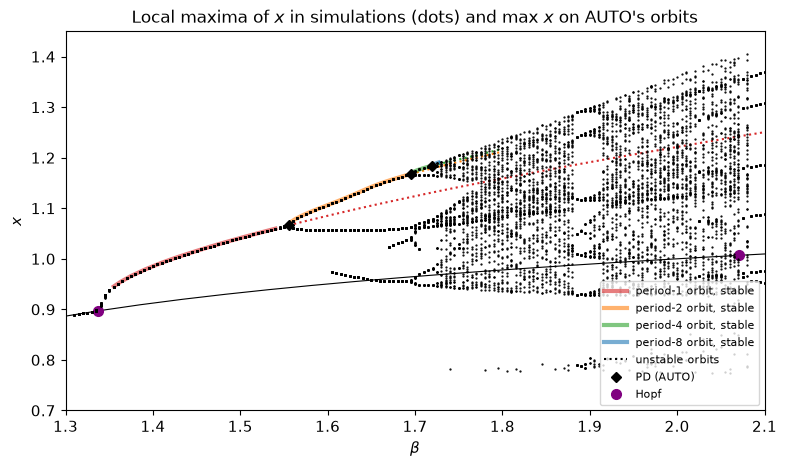

In [41]:
betas = np.linspace(1.3, 2.1, 161)
fig, ax = plt.subplots(figsize=(8, 4.8))
for b in betas:
    tr = m.run(keep=False, beta=b, x=0.9, x0=0.9, total=500, trans=300)
    x = tr["x"]
    pk = x[1:-1][(x[1:-1] > x[:-2]) & (x[1:-1] >= x[2:])]
    ax.plot(np.full(len(pk), b), pk, "k.", ms=1.2, zorder=3)
ax.plot([p.x for p in eqs], [p.u0["x"] for p in eqs], "k-", lw=0.8)
for k, (c, col) in enumerate(zip(branches, ["tab:red", "tab:orange", "tab:green", "tab:blue"])):
    xs = np.array([p.x for p in c])
    ys = np.array([p.umax["x"] for p in c])
    st = np.array([p.stable for p in c])
    ax.plot(xs, np.where(st, ys, np.nan), "-", color=col, lw=3, alpha=0.6, label=f"period-{2**k} orbit, stable")
    ax.plot(xs, np.where(st, np.nan, ys), ":", color=col, lw=1.5)
ax.plot([], [], "k:", lw=1.5, label="unstable orbits")
ax.plot([p.x for p in pds], [p.umax["x"] for p in pds], "kD", ms=5, label="PD (AUTO)")
ax.plot([p.x for p in hb], [p.u0["x"] for p in hb], "o", color="purple", ms=7, label="Hopf")
ax.set(xlim=(1.3, 2.1), ylim=(0.7, 1.45), xlabel=r"$\beta$", ylabel="$x$",
       title="Local maxima of $x$ in simulations (dots) and max $x$ on AUTO's orbits")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "orbit_diagram.png")


def sim_period(b, level=1.0):
    tr = m.run(keep=False, beta=b, x=0.9, x0=0.9, total=700, trans=500)
    t, x = tr.t, tr["x"]
    up = np.where((x[:-1] < level) & (x[1:] >= level))[0]
    tc = t[up] + (level - x[up]) / (x[up + 1] - x[up]) * (t[up + 1] - t[up])
    return tc, x

### Checks

* Hopf points: the linearisation at $x^*$ is
  $\dot u = -u + c\,u(t-\tau)$ with $c = f'(x^*) = (10 - 9\beta)/\beta$, so
  $\lambda = -1 + c\,e^{-\lambda\tau}$. With $\lambda = i\omega$ and
  $\tau = 2$: $c\cos 2\omega = 1$ and $-c\sin 2\omega = \omega$, hence

$$
\tan 2\omega = -\omega, \qquad 2\omega \in \bigl(\tfrac{\pi}{2}, \pi\bigr) + 2\pi k, \qquad
c = -\sqrt{1 + \omega^2}, \qquad \beta = \frac{10}{9 + c},
$$

  and the period there is $2\pi/\omega$.
* The three PD points against the reference values, each with a Floquet
  multiplier $-1$; the first orbit of each doubled branch has twice the period
  at its PD.
* The PD curve passes $\beta = 2$ at $\tau = 1.324922$.
* Simulations: $x$ crosses 1 upwards once per loop; the period-2 orbit at
  $\beta = 1.65$ makes two loops. The periods at $\beta = 1.5$ and $1.65$ match
  the AUTO branches.

In [42]:
for k, p in enumerate(hb):
    lo, hi = (np.pi / 2 + 2 * k * np.pi) / 2 + 1e-9, (np.pi + 2 * k * np.pi) / 2 - 1e-9
    for _ in range(80):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if np.tan(2 * mid) + mid < 0 else (lo, mid)
    w = (lo + hi) / 2
    check(f"Hopf point {k + 1} (characteristic equation)", p.x, 10 / (9 - np.sqrt(1 + w * w)), 2e-5)
    check(f"period at Hopf point {k + 1} = 2 pi / w", p.period, 2 * np.pi / w, 1e-3)
for pd, ref in zip(pds, (1.5554491, 1.6958309, 1.7199016)):
    check(f"PD at beta = {ref}", pd.x, ref, 1e-6)
    check("  Floquet multiplier there = -1", pd.multipliers[0].real, -1, 1e-4)
for k in range(1, 4):
    check(f"first period-{2**k} orbit has twice the period at the PD", branches[k][0].period,
          2 * pds[k - 1].period, 0.01 * pds[k - 1].period)
check("PD curve passes beta = 2 at tau", tau_at_2, 1.324922, 1e-5)
for b, k in ((1.5, 0), (1.65, 1)):
    tc, x = sim_period(b)
    c = branches[k]
    T_auto = np.interp(b, [p.x for p in c], [p.period for p in c])
    check(f"period at beta = {b}: simulation vs AUTO period-{2**k} branch",
          np.mean(tc[2**k:] - tc[:-2**k]), T_auto, 2e-3)
checks_done()

  ok   Hopf point 1 (characteristic equation): 1.33686 (expected 1.33686)
  ok   period at Hopf point 1 = 2 pi / w: 5.49007 (expected 5.49006)
  ok   Hopf point 2 (characteristic equation): 2.07029 (expected 2.07029)
  ok   period at Hopf point 2 = 2 pi / w: 1.55214 (expected 1.55214)
  ok   PD at beta = 1.5554491: 1.55545 (expected 1.55545)
  ok     Floquet multiplier there = -1: -1 (expected -1)
  ok   PD at beta = 1.6958309: 1.69583 (expected 1.69583)
  ok     Floquet multiplier there = -1: -1 (expected -1)
  ok   PD at beta = 1.7199016: 1.7199 (expected 1.7199)
  ok     Floquet multiplier there = -1: -1 (expected -1)
  ok   first period-2 orbit has twice the period at the PD: 11.0161 (expected 11.0124)
  ok   first period-4 orbit has twice the period at the PD: 23.7289 (expected 23.7348)
  ok   first period-8 orbit has twice the period at the PD: 47.1868 (expected 47.1884)
  ok   PD curve passes beta = 2 at tau: 1.32492 (expected 1.32492)


  ok   period at beta = 1.5: simulation vs AUTO period-1 branch: 5.51986 (expected 5.51979)


  ok   period at beta = 1.65: simulation vs AUTO period-2 branch: 11.6515 (expected 11.6509)

37_mackey-glass-period-doubling: 16/16 checks passed


<a id="stuart-landau-single"></a>
## 38. A Stuart–Landau oscillator with delayed self-feedback: folds and tori of waves

$$
\dot z = (\mu + i\omega)\,z - |z|^2 z + \kappa\,z(t-\tau), \qquad z = x + iy,
$$

with $\mu = 1$, $\omega = 10$, $\kappa = 0.8$. A limit-cycle oscillator that
feeds its own past state back. Its periodic solutions are rotating waves
$z = r\,e^{i\Omega t}$ with

$$
\Omega = \omega - \kappa\sin(\Omega\tau), \qquad r^2 = \mu + \kappa\cos(\Omega\tau),
$$

so for larger $\tau$ there are several waves at once: the branch of waves
followed in $\tau$ folds back and forth. The folds are exact:

$$
1 + \kappa\tau\cos(\Omega\tau) = 0,
$$

at $\tau = 1.560254$, $1.582413$, $2.153950$, $2.250648$, $2.741942$,
$2.926149$, …

We simulate one period of the stable wave at $\tau = 1$ and continue it in
$\tau$ with XPP 8.2's periodic-orbit solver for delay equations, which
computes the Floquet multipliers and locates folds (LP) and torus points (TR).
The branch and the folds are checked against the exact formulas, and the
torus points independently in a frame rotating with the wave.

In [43]:
import re

section("38_stuart-landau-single")

### The model

In real form, with the histories `x0`, `y0`. The run keeps only its last
$0.582759$ time units (`trans`): one period of the wave at $\tau = 1$, which
AUTO then takes as its starting orbit.

In [44]:
MU, OM, KAP = 1.0, 10.0, 0.8
mb = (ModelBuilder("stuart_landau_delay")
      .comment("Stuart-Landau oscillator with delayed self-feedback")
      .ode("x", "mu*x-om*y+kappa*delay(x,tau)-(x^2+y^2)*x")
      .ode("y", "om*x+mu*y+kappa*delay(y,tau)-(x^2+y^2)*y")
      .parameter(tau=1, mu=MU, om=OM, kappa=KAP, x0=1, y0=0)
      .initial_value("x", "x0")
      .initial_value("y", "y0")
      .initial(x=1, y=0)
      .option(delay=4, meth="rk4", total=300, trans=299.417241, dt=0.002, maxstor=200000))
print(mb.render())
m = mb.load(ODE)
m.auto.parameters("tau", "mu", "om", "kappa")

# Stuart-Landau oscillator with delayed self-feedback
x'=mu*x-om*y+kappa*delay(x,tau)-(x^2+y^2)*x
y'=om*x+mu*y+kappa*delay(y,tau)-(x^2+y^2)*y
par tau=1,mu=1.0,om=10.0,kappa=0.8,x0=1,y0=0
x(0)=x0
y(0)=y0
init x=1,y=0
@ delay=4,meth=rungekutta,total=300,trans=299.417241,dt=0.002,maxstor=200000
done



### One period of the wave, then the branch in $\tau$

`start="periodic"` starts AUTO from the orbit just computed. The wave is a
circle of radius $r$: XPP's norm (the root mean square of $(x, y)$ over the
mesh) is $r$, while the maximum of $x$ over the mesh points misses the top of
the circle slightly. This takes about a minute.

In [45]:
m.run()
waves = m.auto.run("tau", start="periodic", ds=0.01, dsmax=0.05, ntst=10, ncol=3,
                   parmin=0.5, parmax=3.0, nmax=600)
taus = np.array([p.x for p in waves])
Om = 2 * np.pi / np.array([p.period for p in waves])
rad = np.array([p.norm for p in waves])
stab = np.array([p.stable for p in waves])
lps, trs = waves.special("LP"), waves.special("TR")
print(f"{len(waves)} waves; folds at tau = {[round(p.x, 6) for p in lps]}")
print(f"torus points at tau = {[round(p.x, 5) for p in trs]}")

135 waves; folds at tau = [1.582413, 1.560254, 2.250648, 2.15395, 2.926149, 2.741942]
torus points at tau = [1.58211, 1.56066, 2.24993, 2.15441, 2.92376, 2.74358]


### Torus points, seen in the rotating frame

Writing $z = e^{iWt}\,w$ turns the wave into the equilibrium $w = r$ of

$$
\dot w = \bigl(\mu + i(\omega - W)\bigr)\,w - |w|^2 w + \kappa\,e^{-iW\tau}\,w(t-\tau).
$$

That equilibrium lies on a circle of equilibria (any phase), which XPP's
Newton step cannot handle; the extra term $-10^{-6}q$ pins the phase and
moves the zero root only to $-10^{-6}$. The second model is written to its own
file next to `ODE`.

At a torus point a pair of characteristic roots $\pm i\nu$ of this
equilibrium lies on the imaginary axis, and the complex Floquet multipliers of
the wave are $e^{\pm i\nu T}$ ($T$ the period): their angles must agree.
`rotating_roots(p)` polishes $W$ on $\Omega = \omega - \kappa\sin(\Omega\tau)$
by Newton's method, sets the rotating model to the wave of point `p`, and
reads XPP's characteristic roots (*Sing pts*, "Print eigenvalues").

In [46]:
rot = (ModelBuilder("stuart_landau_rotating")
       .ode("p", "mu*p-(om-w)*q-(p^2+q^2)*p+kappa*cos(w*tau)*delay(p,tau)+kappa*sin(w*tau)*delay(q,tau)")
       .ode("q", "(om-w)*p+mu*q-(p^2+q^2)*q+kappa*cos(w*tau)*delay(q,tau)-kappa*sin(w*tau)*delay(p,tau)"
            "-1e-6*q")
       .parameter(tau=1, mu=MU, om=OM, kappa=KAP, w=10.78)
       .initial(p=1, q=0)
       .option(delay=4))
mr = rot.load(ODE.with_name(f"{NAME}_rotating.ode"))


def rotating_roots(p):
    tau, W = p.x, 2 * np.pi / p.period
    for _ in range(20):
        W -= (W - OM + KAP * np.sin(W * tau)) / (1 + KAP * tau * np.cos(W * tau))
    mr.set(tau=tau, w=W, p=np.sqrt(MU + KAP * np.cos(W * tau)), q=0)
    n0 = len(mr.log)
    mr.press("s", "g", True)
    rows = re.findall(r"^\s*\d+:\s+(\S+)\s+([+-])\s+i\s+(\S+)", mr.log[n0:], re.M)
    return np.array([float(a) + 1j * (1 if s == "+" else -1) * float(b) for a, s, b in rows])


tr_info = []
for p in trs:
    z = rotating_roots(p)
    pair = z[np.abs(z.imag) > 1e-3][0]
    nu = abs(pair.imag)
    mu_c = [e for e in p.multipliers if abs(e.imag) > 1e-6]
    th_floq = abs(np.angle(mu_c[0]))
    th_root = abs(np.angle(np.exp(1j * nu * p.period)))
    tr_info.append((p, pair, th_floq, th_root, z))
    print(f"  TR at tau = {p.x:.5f}: rotating-frame pair {pair.real:+.1e} +- {nu:.5f} i; "
          f"angle of exp(i nu T) {th_root:.6f}, of the Floquet multipliers {th_floq:.6f}")

  TR at tau = 1.58211: rotating-frame pair -5.1e-07 +- 1.11911 i; angle of exp(i nu T) 0.734981, of the Floquet multipliers 0.734980


  TR at tau = 1.56066: rotating-frame pair -2.4e-06 +- 1.08319 i; angle of exp(i nu T) 0.654000, of the Floquet multipliers 0.653996


  TR at tau = 2.24993: rotating-frame pair -2.2e-07 +- 1.31917 i; angle of exp(i nu T) 0.891610, of the Floquet multipliers 0.891610


  TR at tau = 2.15441: rotating-frame pair +3.0e-06 +- 1.32837 i; angle of exp(i nu T) 0.780942, of the Floquet multipliers 0.780946


  TR at tau = 2.92376: rotating-frame pair -1.3e-07 +- 1.19623 i; angle of exp(i nu T) 0.813837, of the Floquet multipliers 0.813837


  TR at tau = 2.74358: rotating-frame pair -2.1e-06 +- 1.23312 i; angle of exp(i nu T) 0.720460, of the Floquet multipliers 0.720458


### Figures

Frequency and amplitude of the waves along the branch, on top of the exact
family (parametrised by $\theta = \Omega\tau$), and the rotating-frame roots
at the third torus point.

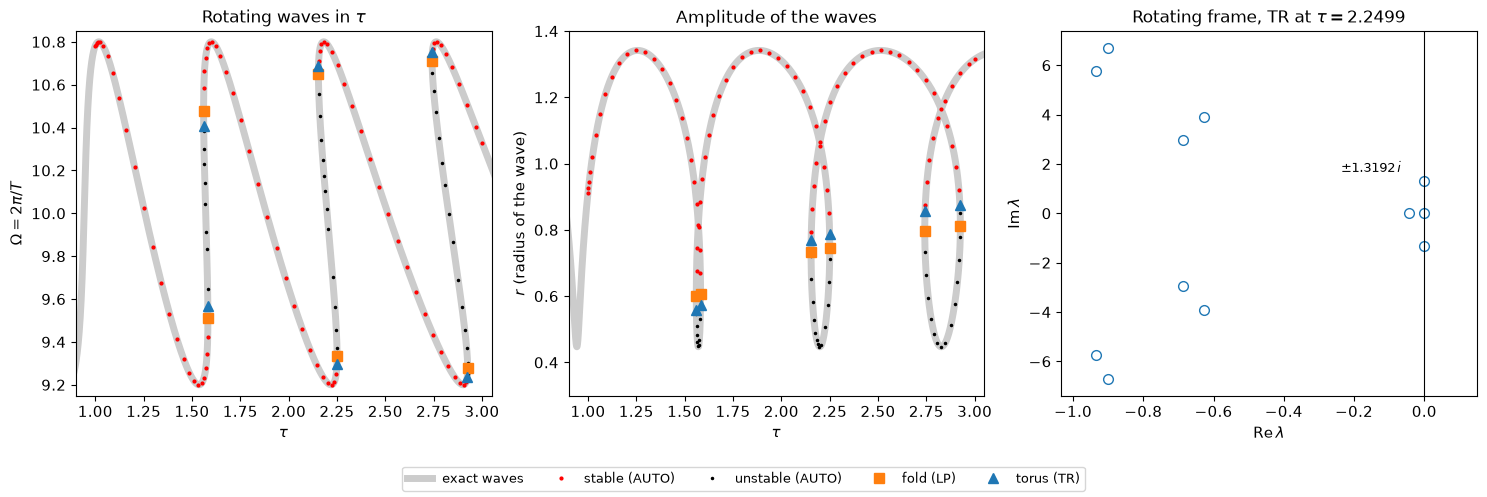

In [47]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
th = np.linspace(0, 40, 4000)
W = OM - KAP * np.sin(th)
for ax, yy, yex, lab in ((axs[0], Om, W, r"$\Omega = 2\pi/T$"),
                         (axs[1], rad, np.sqrt(MU + KAP * np.cos(th)), "$r$ (radius of the wave)")):
    ax.plot(th / W, yex, color="0.8", lw=5, label="exact waves")
    ax.plot(taus, np.where(stab, yy, np.nan), "r.", ms=4, label="stable (AUTO)")
    ax.plot(taus, np.where(stab, np.nan, yy), "k.", ms=3, label="unstable (AUTO)")
    sel = lambda ps: yy[[q.index - waves[0].index for q in ps]]
    ax.plot([p.x for p in lps], sel(lps), "s", color="tab:orange", ms=7, label="fold (LP)")
    ax.plot([p.x for p in trs], sel(trs), "^", color="tab:blue", ms=7, label="torus (TR)")
    ax.set(xlim=(0.9, 3.05), xlabel=r"$\tau$", ylabel=lab)
axs[0].set_ylim(9.15, 10.85)
axs[1].set_ylim(0.3, 1.4)
fig.legend(*axs[0].get_legend_handles_labels(), loc="lower center", ncol=5)
axs[0].set_title(r"Rotating waves in $\tau$")
axs[1].set_title("Amplitude of the waves")
p, pair, _, _, z = tr_info[2]
axs[2].plot(z.real, z.imag, "o", mfc="none", ms=7)
axs[2].axvline(0, color="k", lw=0.8)
axs[2].set(xlim=(z.real.min() - 0.1, 0.15), xlabel=r"$\mathrm{Re}\,\lambda$", ylabel=r"$\mathrm{Im}\,\lambda$",
           title=rf"Rotating frame, TR at $\tau = {p.x:.4f}$")
axs[2].annotate(rf"$\pm{abs(pair.imag):.4f}\,i$", (0, abs(pair.imag)), xytext=(-60, 6),
                textcoords="offset points", fontsize=9)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(FIG / "waves.png")

### Checks

* On the whole branch, $\bigl|\Omega - \omega + \kappa\sin(\Omega\tau)\bigr|$
  and $\bigl|r^2 - \mu - \kappa\cos(\Omega\tau)\bigr|$ vanish (to $10^{-5}$
  and $10^{-4}$).
* The six folds against the values listed above, and
  $1 + \kappa\tau\cos(\Omega\tau) = 0$ at each.
* Six torus points; at each, the rotating-frame pair lies on the imaginary
  axis and the angle of $e^{i\nu T}$ equals that of the Floquet multipliers.

In [48]:
check("largest |Omega - om + kappa sin(Omega tau)| on the branch",
      np.max(np.abs(Om - OM + KAP * np.sin(Om * taus))), 0, 1e-5)
check("largest |r^2 - mu - kappa cos(Omega tau)| on the branch",
      np.max(np.abs(rad**2 - MU - KAP * np.cos(Om * taus))), 0, 1e-4)
for ref in (1.560254, 1.582413, 2.153950, 2.250648, 2.741942, 2.926149):
    p = min(lps, key=lambda q: abs(q.x - ref))
    W = 2 * np.pi / p.period
    check(f"fold at tau = {ref}", p.x, ref, 2e-6)
    check("  1 + kappa tau cos(Omega tau) there", 1 + KAP * p.x * np.cos(W * p.x), 0, 1e-3)
check("number of torus points found", len(trs), 6, 0)
for p, pair, th_f, th_r, _ in tr_info:
    check(f"TR at tau = {p.x:.5f}: Re of the rotating-frame pair", pair.real, 0, 1e-4)
    check("  angle of exp(i nu T) vs Floquet multipliers", th_r, th_f, 1e-4)
checks_done()

  ok   largest |Omega - om + kappa sin(Omega tau)| on the branch: 1.34699e-06 (expected 0)
  ok   largest |r^2 - mu - kappa cos(Omega tau)| on the branch: 6.2455e-06 (expected 0)
  ok   fold at tau = 1.560254: 1.56025 (expected 1.56025)
  ok     1 + kappa tau cos(Omega tau) there: 8.39387e-07 (expected 0)
  ok   fold at tau = 1.582413: 1.58241 (expected 1.58241)
  ok     1 + kappa tau cos(Omega tau) there: -5.35034e-05 (expected 0)
  ok   fold at tau = 2.15395: 2.15395 (expected 2.15395)
  ok     1 + kappa tau cos(Omega tau) there: 2.27655e-05 (expected 0)
  ok   fold at tau = 2.250648: 2.25065 (expected 2.25065)
  ok     1 + kappa tau cos(Omega tau) there: 6.69649e-05 (expected 0)
  ok   fold at tau = 2.741942: 2.74194 (expected 2.74194)
  ok     1 + kappa tau cos(Omega tau) there: -0.000116659 (expected 0)
  ok   fold at tau = 2.926149: 2.92615 (expected 2.92615)
  ok     1 + kappa tau cos(Omega tau) there: 1.41159e-05 (expected 0)
  ok   number of torus points found: 6 (expected 6)


<a id="stuart-landau-pair"></a>
## 39. Two delay-coupled Stuart–Landau oscillators: torus bifurcations of the in-phase wave

$$
\dot z_1 = (1 + i\omega)\,z_1 - |z_1|^2 z_1 + \kappa\,\bigl(z_2(t-\tau) - z_1\bigr), \qquad
\dot z_2 = (1 + i\omega)\,z_2 - |z_2|^2 z_2 + \kappa\,\bigl(z_1(t-\tau) - z_2\bigr),
$$

with $\omega = 1.5$ and first $\kappa = 1$. Two identical oscillators that see
each other with a delay $\tau$. Both can oscillate in phase on the same
circle, $z_1 = z_2 = r\,e^{i\Omega t}$, with

$$
\Omega = \omega - \kappa\sin(\Omega\tau), \qquad r^2 = 1 - \kappa + \kappa\cos(\Omega\tau).
$$

This in-phase wave has period $7.955487$ at $\tau = 1$ and loses stability in
torus (Neimark–Sacker) bifurcations at $\tau = 1.584$ and $2.329$: a pair of
Floquet multipliers leaves the unit circle and a second frequency appears.

We continue the wave in $\tau$ and find the two torus points, check the branch
against the exact formulas and the torus points in a rotating frame, follow
the first torus point in $(\tau, \kappa)$ up to $\kappa = 1.2$ (checking the
end of that curve with a second branch of waves at $\kappa = 1.2$), and
simulate on both sides of the first torus point.

In [49]:
import re

section("39_stuart-landau-pair")

### The model

The histories of $x_1$, $x_2$ are the parameters `h1`, `h2` ($y_1$, $y_2$
start at 0). The run keeps only its last $7.955487$ time units: one period of
the in-phase wave at $\tau = 1$. `exact_wave(tau, kappa, W)` solves
$\Omega = \omega - \kappa\sin(\Omega\tau)$ by Newton's method from $W$ and
returns $\Omega$ and $r$.

In [50]:
OM = 1.5
mb = (ModelBuilder("stuart_landau_pair")
      .comment("two delay-coupled Stuart-Landau oscillators")
      .ode("x1", "x1-om*y1-(x1^2+y1^2)*x1+kappa*(delay(x2,tau)-x1)")
      .ode("y1", "om*x1+y1-(x1^2+y1^2)*y1+kappa*(delay(y2,tau)-y1)")
      .ode("x2", "x2-om*y2-(x2^2+y2^2)*x2+kappa*(delay(x1,tau)-x2)")
      .ode("y2", "om*x2+y2-(x2^2+y2^2)*y2+kappa*(delay(y1,tau)-y2)")
      .parameter(tau=1, kappa=1, om=OM, h1=1, h2=1)
      .initial_value("x1", "h1")
      .initial_value("x2", "h2")
      .initial(x1=1, y1=0, x2=1, y2=0)
      .option(delay=4, meth="rk4", total=600, trans=592.044513, dt=0.01, maxstor=100000))
print(mb.render())
m = mb.load(ODE)
m.auto.parameters("tau", "kappa", "om")


def exact_wave(tau, kappa, W):
    for _ in range(30):
        W -= (W - OM + kappa * np.sin(W * tau)) / (1 + kappa * tau * np.cos(W * tau))
    return W, np.sqrt(1 - kappa + kappa * np.cos(W * tau))

# two delay-coupled Stuart-Landau oscillators
x1'=x1-om*y1-(x1^2+y1^2)*x1+kappa*(delay(x2,tau)-x1)
y1'=om*x1+y1-(x1^2+y1^2)*y1+kappa*(delay(y2,tau)-y1)
x2'=x2-om*y2-(x2^2+y2^2)*x2+kappa*(delay(x1,tau)-x2)
y2'=om*x2+y2-(x2^2+y2^2)*y2+kappa*(delay(y1,tau)-y2)
par tau=1,kappa=1,om=1.5,h1=1,h2=1
x1(0)=h1
x2(0)=h2
init x1=1,y1=0,x2=1,y2=0
@ delay=4,meth=rungekutta,total=600,trans=592.044513,dt=0.01,maxstor=100000
done



### The in-phase wave in $\tau$, $\kappa = 1$

In [51]:
m.run()
br = m.auto.run("tau", start="periodic", ds=0.01, dsmax=0.05, ntst=15, parmin=0.5, parmax=2.6, nmax=300)
trs = br.special("TR")
bt = np.array([p.x for p in br])
bT = np.array([p.period for p in br])
br_st = np.array([p.stable for p in br])
print(f"{len(br)} waves; torus points at tau = {[round(p.x, 5) for p in trs]}")

39 waves; torus points at tau = [1.58404, 2.32897]


### The rotating frame

With $z_j = e^{iWt}\,w_j$ the wave becomes the equilibrium $w_1 = w_2 = r$ of
a delay equation for $w_j = p_j + iq_j$. Its phase is free (a circle of
equilibria); the term $-10^{-6}q_1$ pins it so that XPP's Newton step works,
and moves the zero root to about $-10^{-6}$. At a torus point a complex pair
of characteristic roots of this equilibrium crosses the imaginary axis;
`rotating_roots` returns the complex pair nearest the axis.

In [52]:
c_, s_ = "kappa*cos(w*tau)", "kappa*sin(w*tau)"
rot = ModelBuilder("stuart_landau_pair_rotating").parameter(tau=1, kappa=1, om=OM, w=0.79)
for j, k in ((1, 2), (2, 1)):
    rot.ode(f"p{j}", f"p{j}-(om-w)*q{j}-(p{j}^2+q{j}^2)*p{j}+{c_}*delay(p{k},tau)+{s_}*delay(q{k},tau)-kappa*p{j}")
    rot.ode(f"q{j}", f"(om-w)*p{j}+q{j}-(p{j}^2+q{j}^2)*q{j}+{c_}*delay(q{k},tau)-{s_}*delay(p{k},tau)-kappa*q{j}"
            + ("-1e-6*q1" if j == 1 else ""))
rot.initial(p1=1, q1=0, p2=1, q2=0).option(delay=4)
mr = rot.load(ODE.with_name(f"{NAME}_rotating.ode"))


def rotating_roots(tau, kappa, period):
    W, r = exact_wave(tau, kappa, 2 * np.pi / period)
    mr.set(tau=tau, kappa=kappa, w=W, p1=r, q1=0, p2=r, q2=0)
    n0 = len(mr.log)
    mr.press("s", "g", True)
    rows = re.findall(r"^\s*\d+:\s+(\S+)\s+([+-])\s+i\s+(\S+)", mr.log[n0:], re.M)
    z = np.array([float(a) + 1j * (1 if s == "+" else -1) * float(b) for a, s, b in rows])
    cz = z[np.abs(z.imag) > 1e-3]
    return cz[np.argmin(np.abs(cz.real))]


pairs = [rotating_roots(p.x, 1.0, p.period) for p in trs]
for p, z in zip(trs, pairs):
    print(f"  TR at tau = {p.x:.6f}: rotating-frame pair {z.real:+.1e} +- {abs(z.imag):.5f} i")

  TR at tau = 1.584035: rotating-frame pair -1.3e-09 +- 1.11939 i
  TR at tau = 2.328968: rotating-frame pair +3.8e-06 +- 1.74503 i


### The torus curve in $(\tau, \kappa)$, and a check of its end at $\kappa = 1.2$

The first torus point is followed in $(\tau, \kappa)$ until it leaves the
*Two par* window at $\kappa = 1.2$ (about 40 s); every 8th point is checked in
the rotating frame. Then, independently: from the first wave
($\tau = 1$, $\kappa = 1$) we continue in $\kappa$ up to $1.2$ (*Extend* of a
stored delay orbit in another parameter), and from there in $\tau$; that
branch's torus point must sit at the end of the torus curve.

In [53]:
m.auto.axes(plot="two_par", param="tau", param2="kappa", xmin=1.3, xmax=2.5, ymin=0.7, ymax=1.2)
tcurve = m.auto.run(grab=trs[0].label, choice="two param", ds=0.02, dsmax=0.1, nmax=200)
end = tcurve[-1]
print(f"torus curve: {len(tcurve)} points from (tau, kappa) = (1.5840, 1) to ({end.x:.6f}, "
      f"{end.par['kappa']:.6f})")
curve_pairs = [rotating_roots(p.x, p.par["kappa"], p.period) for p in tcurve[::8]]
m.set(tau=1.0, kappa=1.0)
m.auto.axes(plot="hi", param="kappa")
k_br = m.auto.run(grab=br[0].label, choice="extend", ds=0.01, dsmax=0.05, parmin=0.5, parmax=1.2, nmax=100)
m.auto.axes(plot="hi", param="tau")
br12 = m.auto.run(grab=k_br[-1].label, choice="extend", ds=0.01, dsmax=0.05, parmin=0.5, parmax=2.0, nmax=300)
tr12 = br12.special("TR")
print(f"wave at kappa = {k_br[-1].x:.4f}: torus point at tau = {[round(p.x, 6) for p in tr12]}")
m.set(tau=1.0, kappa=1.0)

torus curve: 56 points from (tau, kappa) = (1.5840, 1) to (1.647033, 1.200000)


wave at kappa = 1.2000: torus point at tau = [1.647033]


<pyxpp.Model 39_stuart-landau-pair.ode: vars=['X1', 'Y1', 'X2', 'Y2'] aux=[] pars=5>

### Simulations on both sides of the first torus point ($\kappa = 1$)

Start near the in-phase wave ($x_1 = 1$, $x_2 = 0.9$) and watch the distance
$|z_1 - z_2|$: at $\tau = 1.4$ it decays, at $\tau = 1.8$ it does not. XPP
stores solutions in single precision, so below about $10^{-7}$ there is only
rounding noise.

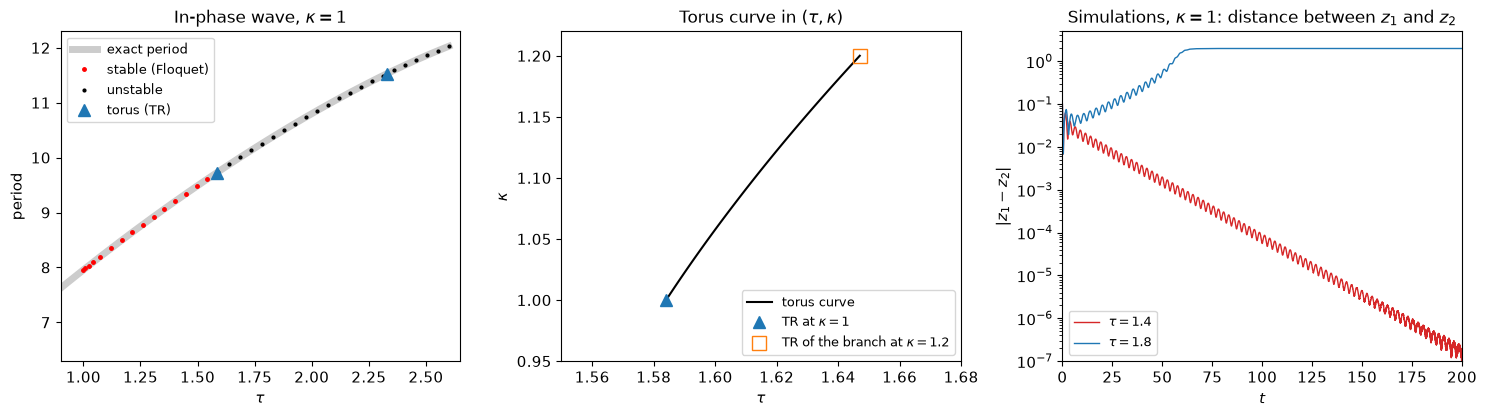

In [54]:
sims = {}
for tau in (1.4, 1.8):
    tr = m.run(keep=False, tau=tau, kappa=1.0, h1=1.0, x1=1.0, h2=0.9, x2=0.9, total=400, trans=0)
    sims[tau] = (tr.t, np.hypot(tr["x1"] - tr["x2"], tr["y1"] - tr["y2"]))

fig, axs = plt.subplots(1, 3, figsize=(15, 4.3))
tt = np.linspace(0.6, 2.6, 400)
W0 = np.array([exact_wave(t, 1.0, 2 * np.pi / np.interp(t, bt, bT))[0] for t in tt])
axs[0].plot(tt, 2 * np.pi / W0, color="0.8", lw=5, label="exact period")
axs[0].plot(bt[br_st], bT[br_st], "r.", ms=5, label="stable (Floquet)")
axs[0].plot(bt[~br_st], bT[~br_st], "k.", ms=4, label="unstable")
axs[0].plot([p.x for p in trs], [p.period for p in trs], "^", color="tab:blue", ms=9, label="torus (TR)")
axs[0].set(xlim=(0.9, 2.65), xlabel=r"$\tau$", ylabel="period", title=r"In-phase wave, $\kappa = 1$")
axs[0].legend()
axs[1].plot([p.x for p in tcurve], [p.par["kappa"] for p in tcurve], "k-", lw=1.5, label="torus curve")
axs[1].plot([p.x for p in trs[:1]], [1.0], "^", color="tab:blue", ms=9, label=r"TR at $\kappa = 1$")
axs[1].plot([p.x for p in tr12], [1.2] * len(tr12), "s", color="tab:orange", mfc="none", ms=10,
            label=r"TR of the branch at $\kappa = 1.2$")
axs[1].set(xlim=(1.55, 1.68), ylim=(0.95, 1.22), xlabel=r"$\tau$", ylabel=r"$\kappa$",
           title=r"Torus curve in $(\tau, \kappa)$")
axs[1].legend(loc="lower right")
for tau, col in ((1.4, "tab:red"), (1.8, "tab:blue")):
    axs[2].semilogy(*sims[tau], color=col, lw=1, label=rf"$\tau = {tau}$")
axs[2].set(xlim=(0, 200), ylim=(1e-7, 5), xlabel="$t$", ylabel=r"$|z_1 - z_2|$",
           title=r"Simulations, $\kappa = 1$: distance between $z_1$ and $z_2$")
axs[2].legend()
fig.tight_layout()
fig.savefig(FIG / "torus.png")

### Checks

* The period of the in-phase wave at $\tau = 1$, $7.955487$.
* Along the branch, $\Omega = 2\pi/T$ against the exact $\Omega$, and the
  radius: XPP's norm is the root mean square of $(x_1, y_1, x_2, y_2)$ over
  the orbit, which is $\sqrt2\,r$ here.
* The torus points near $\tau = 1.584$ and $2.329$, with the rotating-frame
  pair on the imaginary axis there.
* The torus curve ends on the window's edge $\kappa = 1.2$; the rotating-frame
  pair stays on the imaginary axis along it; and the torus point of the
  independent branch at $\kappa = 1.2$ coincides with the curve's end.
* The perturbation of the in-phase wave decays at $\tau = 1.4$ (to below
  $10^{-3}$ of its start) but not at $\tau = 1.8$.

In [55]:
check("period of the in-phase wave at tau = 1", br[0].period, 7.955487, 1e-5)
err = [abs(2 * np.pi / p.period - exact_wave(p.x, 1.0, 2 * np.pi / p.period)[0]) for p in br]
check("largest |Omega - exact Omega| on the branch", max(err), 0, 1e-5)
err = [abs(p.norm / np.sqrt(2) - exact_wave(p.x, 1.0, 2 * np.pi / p.period)[1]) for p in br]
check("largest |norm / sqrt(2) - r| on the branch", max(err), 0, 1e-4)
for p, ref, z in zip(trs, (1.584, 2.329), pairs):
    check(f"torus point near tau = {ref}", p.x, ref, 5e-4)
    check("  Re of the rotating-frame pair there", z.real, 0, 1e-4)
check("torus curve ends on the box edge kappa = 1.2", end.par["kappa"], 1.2, 1e-6)
check("rotating frame: largest |Re| of the pair along the torus curve",
      max(abs(z.real) for z in curve_pairs), 0, 1e-4)
check("torus point of the wave branch at kappa = 1.2 vs end of the torus curve",
      tr12[0].x if tr12 else np.nan, end.x, 1e-4)
d14, d18 = sims[1.4][1], sims[1.8][1]
check("tau = 1.4: perturbation of the in-phase wave decays (final / initial)", d14[-1] / d14[0], 0, 1e-3)
check("tau = 1.8: it does not (final distance > 0.1; 1 = yes)", float(d18[-1000:].max() > 0.1), 1, 0)
checks_done()

  ok   period of the in-phase wave at tau = 1: 7.95549 (expected 7.95549)
  ok   largest |Omega - exact Omega| on the branch: 2.43034e-08 (expected 0)
  ok   largest |norm / sqrt(2) - r| on the branch: 4.37039e-08 (expected 0)
  ok   torus point near tau = 1.584: 1.58404 (expected 1.584)
  ok     Re of the rotating-frame pair there: -1.27857e-09 (expected 0)
  ok   torus point near tau = 2.329: 2.32897 (expected 2.329)
  ok     Re of the rotating-frame pair there: 3.79656e-06 (expected 0)
  ok   torus curve ends on the box edge kappa = 1.2: 1.2 (expected 1.2)
  ok   rotating frame: largest |Re| of the pair along the torus curve: 2.15193e-06 (expected 0)
  ok   torus point of the wave branch at kappa = 1.2 vs end of the torus curve: 1.64703 (expected 1.64703)
  ok   tau = 1.4: perturbation of the in-phase wave decays (final / initial): 0 (expected 0)
  ok   tau = 1.8: it does not (final distance > 0.1; 1 = yes): 1 (expected 1)

39_stuart-landau-pair: 12/12 checks passed


## Summary

All checks of this notebook:

In [56]:
for name, r in results.items():
    print(f"{name:40s} {sum(r):3d}/{len(r)}")
n_ok = sum(sum(r) for r in results.values())
n = sum(len(r) for r in results.values())
print(f"\n{n_ok}/{n} checks passed")

32_two-delays                             15/15
33_hutchinson-periodic-orbits             10/10
34_cusp-delay                             16/16
35_marcus-westervelt                      13/13
36_wilson-cowan-delay                     16/16
37_mackey-glass-period-doubling           16/16
38_stuart-landau-single                   27/27
39_stuart-landau-pair                     12/12

125/125 checks passed
